In [1]:
import json, time
from datetime import datetime, timezone
from pathlib import Path

import pandas as pd
import requests

API_URL = "https://api.obis.org/v3/occurrence"
SPECIES = "Megaptera novaeangliae"

# North Atlantic bounding box (the same box is used for every dataset)
LON_MIN, LON_MAX = -85, 40
LAT_MIN, LAT_MAX = 10, 80
WKT = (f"POLYGON(({LON_MIN} {LAT_MIN},{LON_MAX} {LAT_MIN},{LON_MAX} {LAT_MAX},"
       f"{LON_MIN} {LAT_MAX},{LON_MIN} {LAT_MIN}))")

params = {"scientificname": SPECIES, "geometry": WKT, "size": 5}
response = requests.get(API_URL, params=params, timeout=120)
print("HTTP status:", response.status_code)
response.raise_for_status()
payload = response.json()

print("Total records matching the query:", payload["total"])
test_df = pd.DataFrame(payload["results"])
print("Columns returned:", len(test_df.columns))
print(test_df.columns.tolist())
print(test_df.head().T.to_string())

HTTP status: 200
Total records matching the query: 103302
Columns returned: 103
['basisOfRecord', 'class', 'classid', 'decimalLatitude', 'decimalLongitude', 'eventDate', 'eventID', 'eventType', 'family', 'familyid', 'genus', 'genusid', 'identificationRemarks', 'infraorder', 'infraorderid', 'infraphylum', 'infraphylumid', 'kingdom', 'kingdomid', 'marine', 'megaclass', 'megaclassid', 'occurrenceID', 'occurrenceStatus', 'order', 'orderid', 'phylum', 'phylumid', 'recordedBy', 'scientificName', 'scientificNameAuthorship', 'scientificNameID', 'species', 'speciesid', 'specificEpithet', 'subclass', 'subclassid', 'suborder', 'suborderid', 'subphylum', 'subphylumid', 'superdomain', 'superdomainid', 'superfamily', 'superfamilyid', 'verbatimEventDate', 'vernacularName', 'id', 'dataset_id', 'node_id', 'dropped', 'absence', 'originalScientificName', 'aphiaID', 'flags', 'bathymetry', 'shoredistance', 'sst', 'sss', 'associatedReferences', 'bibliographicCitation', 'catalogNumber', 'collectionCode', 'co

In [2]:
RAW_DIR = Path("../data/raw/obis_humpback")
RAW_DIR.mkdir(parents=True, exist_ok=True)
PAGE_SIZE = 5000
PAUSE_SECONDS = 0.5

def fetch_page(after=None):
    query = {"scientificname": SPECIES, "geometry": WKT, "size": PAGE_SIZE}
    if after:
        query["after"] = after
    for attempt in range(1, 6):          # retry up to 5 times on network errors
        try:
            r = requests.get(API_URL, params=query, timeout=180)
            r.raise_for_status()
            return r.json()
        except requests.RequestException as err:
            print(f"  attempt {attempt} failed: {err}")
            time.sleep(5 * attempt)
    raise RuntimeError("Giving up after 5 failed attempts. Run the cell again to resume.")

# Resume support: continue after the last saved page
saved = sorted(RAW_DIR.glob("page_*.json"))
after, page_no, finished = None, len(saved), False
if saved:
    last = json.loads(saved[-1].read_text(encoding="utf-8"))
    if last["results"]:
        after = last["results"][-1]["id"]
    finished = len(last["results"]) < PAGE_SIZE   # a short page means the end
    print(f"Resuming: {page_no} pages already saved. finished={finished}")

total_reported = None
while not finished:
    payload = fetch_page(after)
    total_reported = payload.get("total", total_reported)
    results = payload["results"]
    if not results:
        break
    page_no += 1
    (RAW_DIR / f"page_{page_no:04d}.json").write_text(json.dumps(payload), encoding="utf-8")
    after = results[-1]["id"]
    print(f"page {page_no}: {len(results)} records (query total: {total_reported})")
    finished = len(results) < PAGE_SIZE
    time.sleep(PAUSE_SECONDS)

if total_reported is not None:
    meta = {
        "source": "OBIS API v3 /occurrence",
        "api_url": API_URL,
        "species": SPECIES,
        "geometry_wkt": WKT,
        "page_size": PAGE_SIZE,
        "pages": page_no,
        "total_reported_by_api": total_reported,
        "downloaded_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    }
    (RAW_DIR / "download_meta.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    print(meta)

Resuming: 21 pages already saved. finished=True


In [5]:
frames = []
for f in sorted(RAW_DIR.glob("page_*.json")):
    frames.append(pd.DataFrame(json.loads(f.read_text(encoding="utf-8"))["results"]))
obis = pd.concat(frames, ignore_index=True)
print("Records downloaded:", len(obis), "| columns:", obis.shape[1])
print("Duplicate ids:", int(obis["id"].duplicated().sum()))

for col in ["absence", "basisOfRecord", "eventType", "license"]:
    if col in obis.columns:
        print(f"\n=== {col} ===")
        print(obis[col].value_counts(dropna=False).head(10).to_string())

# Which datasets are inside, and what do they look like?
summary = (
    obis.groupby("dataset_id")
        .agg(n_records=("id", "size"),
             dataset_name=("datasetName", "first"),
             event_type=("eventType", lambda s: s.mode().iat[0] if s.notna().any() else None),
             first_year=("date_year", "min"),
             last_year=("date_year", "max"))
        .sort_values("n_records", ascending=False)
)
print("\n=== Datasets (top 25) ===")
print(summary.head(25).to_string())

# Date availability: OBIS parses dates into date_year / date_mid (epoch milliseconds)
print("\nRecords without OBIS date_year:", int(obis["date_year"].isna().sum()))
rescue = obis["date_year"].isna() & obis["verbatimEventDate"].notna()
print("...of which verbatimEventDate is present (rescuable):", int(rescue.sum()))
print("\nRecords per year (last 20):")
print(obis["date_year"].dropna().astype(int).value_counts().sort_index().tail(20).to_string())

# Coordinates
print("\nCoordinate uncertainty missing:", int(obis["coordinateUncertaintyInMeters"].isna().sum()))
print("Longitude range:", obis["decimalLongitude"].min(), obis["decimalLongitude"].max())
print("Latitude range:", obis["decimalLatitude"].min(), obis["decimalLatitude"].max())

Records downloaded: 100185 | columns: 159
Duplicate ids: 0

=== absence ===
absence
False    100185

=== basisOfRecord ===
basisOfRecord
HumanObservation          97691
MachineObservation         1689
Occurrence                  789
materialSample               14
MaterialSample                1
NomenclaturalChecklist        1

=== eventType ===
eventType
NaN                                   79798
Whalewatch                            10805
Observation                            6368
Opportunistic                          1823
Targeted cetacean survey                381
MMO without effort                      325
C&P Marine Mammal Survey Flights        206
Stratified random megafauna survey      127
Transport Canada Survey Flights         113
MMO with effort                         108

=== license ===
license
https://creativecommons.org/publicdomain/zero/1.0          31878
http://creativecommons.org/licenses/by-nc/4.0/             30573
NaN                                            

Dimensions: {'time': 15299, 'zlev': 1, 'latitude': 720, 'longitude': 1440}
time dtype: datetime64[ns]
time first/last: 1981-09-01T12:00:00.000000000 | 2026-10-29T12:00:00.000000000
Last available date: 2026-10-29
lat first/last: -89.875 89.875
lon first/last: -179.875 179.875

Selection check | days: 30 | lat cells: 280 | lon cells: 500
Downloaded in 23.2 seconds | shape: {'time': 30, 'latitude': 280, 'longitude': 500}
File size: 11.8 MB | rough estimate for 2010-2026: 2.4 GB, about 78 minutes


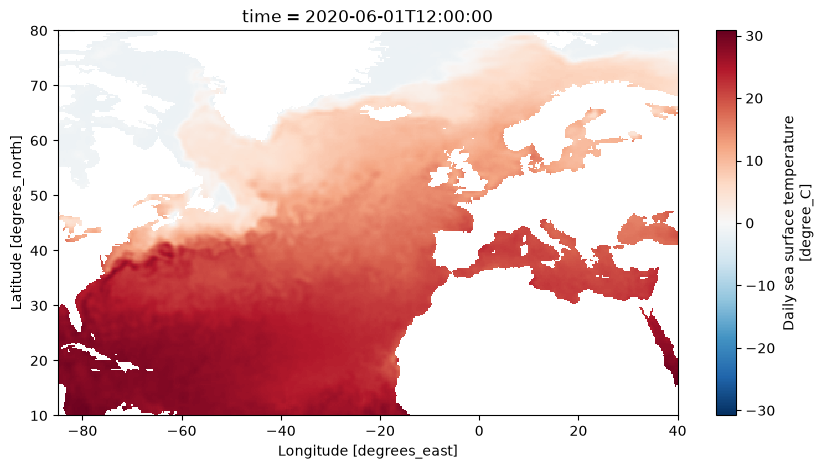

In [6]:
import time
from datetime import datetime, timezone
import xarray as xr
import matplotlib.pyplot as plt

SST_URL = "https://coastwatch.pfeg.noaa.gov/erddap/griddap/ncdcOisst21Agg_LonPM180"
ds = xr.open_dataset(SST_URL)

def sanitize_for_netcdf(dataset, source_url):
    """Drop reserved attributes (names starting with '_') that break to_netcdf,
    and record where and when the data came from."""
    out = dataset.copy()
    out.attrs = {k: v for k, v in out.attrs.items() if not str(k).startswith("_")}
    for name in list(out.variables):
        out[name].attrs = {k: v for k, v in out[name].attrs.items() if not str(k).startswith("_")}
    out.attrs["source_url"] = source_url
    out.attrs["downloaded_utc"] = datetime.now(timezone.utc).isoformat(timespec="seconds")
    return out

print("Dimensions:", dict(ds.sizes))
print("time dtype:", ds["time"].dtype)
print("time first/last:", ds["time"].values[0], "|", ds["time"].values[-1])
print("Last available date:", str(ds["time"].values.max())[:10])
print("lat first/last:", float(ds["latitude"][0]), float(ds["latitude"][-1]))
print("lon first/last:", float(ds["longitude"][0]), float(ds["longitude"][-1]))

def axis_slice(values, lo, hi):
    """Slice that works for ascending and descending coordinates."""
    return slice(lo, hi) if values[0] <= values[-1] else slice(hi, lo)

lat_slice = axis_slice(ds["latitude"].values, LAT_MIN, LAT_MAX)
lon_slice = axis_slice(ds["longitude"].values, LON_MIN, LON_MAX)
T0, T1 = "2020-06-01", "2020-06-30"

n_days = ds["time"].sel(time=slice(T0, T1)).size
n_lat = ds["latitude"].sel(latitude=lat_slice).size
n_lon = ds["longitude"].sel(longitude=lon_slice).size
print(f"\nSelection check | days: {n_days} | lat cells: {n_lat} | lon cells: {n_lon}")

if min(n_days, n_lat, n_lon) == 0:
    print("\nOne axis came back empty, so nothing was downloaded. Copy this whole output to Claude.")
else:
    t0 = time.time()
    small = ds[["sst", "anom"]].sel(
        time=slice(T0, T1), latitude=lat_slice, longitude=lon_slice,
    ).squeeze("zlev", drop=True).load()
    elapsed = time.time() - t0
    print("Downloaded in", round(elapsed, 1), "seconds | shape:", dict(small.sizes))

    out = Path("../data/raw/sst_test_2020-06.nc")
    out.parent.mkdir(parents=True, exist_ok=True)
    enc = {v: {"zlib": True, "complevel": 4, "dtype": "float32"} for v in small.data_vars}
    sanitize_for_netcdf(small, SST_URL).to_netcdf(out, encoding=enc)

    mb = out.stat().st_size / 1e6
    months = 12 * 16 + 10   # 2010-01 .. 2026-10
    print(f"File size: {mb:.1f} MB | rough estimate for 2010-2026: {mb * months / 1000:.1f} GB, about {elapsed * months / 60:.0f} minutes")

    small["sst"].isel(time=0).plot(figsize=(10, 5))
    plt.show()

In [7]:
# --- Cell 4b: download SST + anomaly month by month (resumable) ---
# Needs Cell 1 (LAT_MIN... and Path) and Cell 4 (the opened dataset `ds`, SST_URL and sanitize_for_netcdf).
SST_DIR = Path("../data/raw/sst_oisst")
SST_DIR.mkdir(parents=True, exist_ok=True)

START = pd.Timestamp("2010-01-01")
last_day = pd.Timestamp(ds["time"].values.max()).normalize()   # last day available in this dataset
months = pd.period_range(START, last_day, freq="M")
print("Months to fetch:", len(months), "| last available day:", last_day.date())

enc = {v: {"zlib": True, "complevel": 4, "dtype": "float32"} for v in ["sst", "anom"]}
for p in months:
    out = SST_DIR / f"oisst_{p}.nc"
    if out.exists():
        continue                                   # already downloaded: skip
    t0 = time.time()
    for attempt in range(1, 6):
        try:
            first_day = p.start_time.strftime("%Y-%m-%d")
            end_day = min(p.end_time.normalize(), last_day).strftime("%Y-%m-%d")
            chunk = ds[["sst", "anom"]].sel(
                time=slice(first_day, end_day),
                latitude=slice(LAT_MIN, LAT_MAX),
                longitude=slice(LON_MIN, LON_MAX),
            ).squeeze("zlev", drop=True).load()
            part = Path(str(out) + ".part")
            sanitize_for_netcdf(chunk, SST_URL).to_netcdf(part, encoding=enc)
            part.replace(out)                      # the file only gets its final name when complete
            break
        except Exception as err:
            print(f"  {p} attempt {attempt} failed: {err}")
            time.sleep(5 * attempt)
    else:
        raise RuntimeError(f"Giving up on {p}. Run the cell again to resume.")
    print(f"{p}: {out.stat().st_size / 1e6:.1f} MB in {time.time() - t0:.0f} s")

total_mb = sum(f.stat().st_size for f in SST_DIR.glob("oisst_*.nc")) / 1e6
print(f"Done. {len(list(SST_DIR.glob('oisst_*.nc')))} files, {total_mb / 1000:.2f} GB in total")

Months to fetch: 202 | last available day: 2026-10-29
Done. 202 files, 2.37 GB in total


=== date_source ===
date_source
obis        85531
verbatim    14559
none           95
M/D/Y check: eventDate read as M/D/Y equals verbatimEventDate in 1.000 of 14558 records that have both

Records flagged as month placeholders: 3119

=== precision ===
coord_unc_source
reported         75232
from_decimals    24953
Share precise (<= 12 km): 0.809

=== license_class ===
license_class
CC BY-NC    40549
CC0         32109
unknown     22798
CC BY        2417
CC BY-SA     2245
other          67

=== Profile of the 15 biggest datasets ===
                                          n                              name  year_min  year_max  placeholders  precise_share   license                       institution               recorded_by
dataset_id                                                                                                                                                                                          
03d772f9-454f-42f6-91df-4d1faf2ead16  23909  Happywhale - Humpback wh

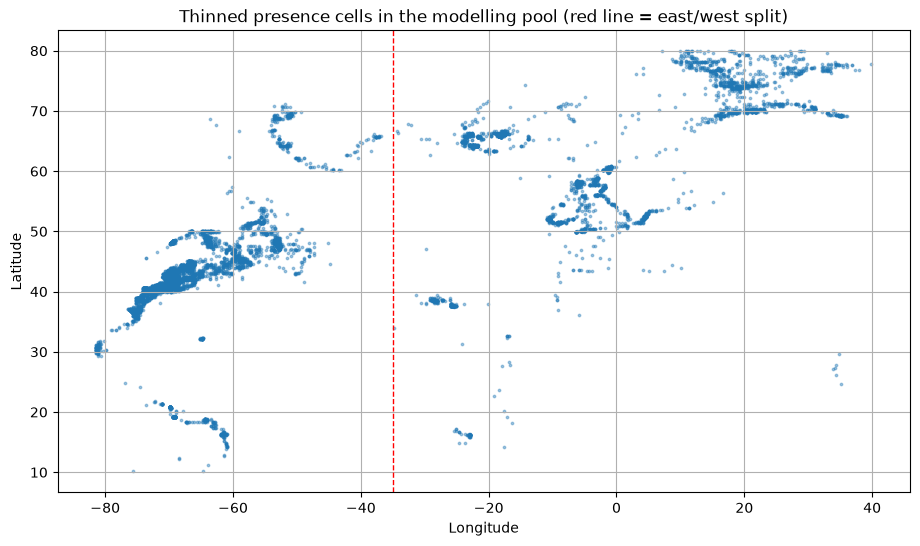


Saved: ..\data\processed\obis_clean_v0.csv and ..\data\processed\presence_cell_month_obis_v0.csv


In [8]:
# --- Cell 5: build a cleaned table from the raw OBIS records (v0 rules) ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

START_YEAR = 2010   # main study period
MIN_LAT = 10        # south of this: probably another population
SPLIT_LON = -35     # east / west split
GRID = 0.25         # degrees (same as the SST grid)
PRECISE_M = 12_000  # "precise coordinate" threshold in metres

o = obis.copy().rename(columns={"decimalLatitude": "lat", "decimalLongitude": "lon"})

# 1) Resolve the observation date: OBIS date -> verbatimEventDate -> eventDate
def iso_date(series):
    return pd.to_datetime(series.astype("string").str.slice(0, 10), format="%Y-%m-%d", errors="coerce")

d_obis = pd.to_datetime(o["date_mid"], unit="ms", errors="coerce").dt.normalize()
d_verb = iso_date(o["verbatimEventDate"])
d_evt_iso = iso_date(o["eventDate"])
d_evt_mdy = pd.to_datetime(o["eventDate"].astype("string").str.slice(0, 10), format="%m/%d/%Y", errors="coerce")

o["date"] = d_obis.fillna(d_verb).fillna(d_evt_iso).fillna(d_evt_mdy)
o["date_source"] = np.select(
    [d_obis.notna(), d_verb.notna(), d_evt_iso.notna(), d_evt_mdy.notna()],
    ["obis", "verbatim", "eventDate_iso", "eventDate_mdy"], default="none")
print("=== date_source ===")
print(o["date_source"].value_counts().to_string())

both = d_verb.notna() & d_evt_mdy.notna()
if both.any():
    agree = float((d_verb[both] == d_evt_mdy[both]).mean())
    print(f"M/D/Y check: eventDate read as M/D/Y equals verbatimEventDate in {agree:.3f} of {int(both.sum())} records that have both")

o["obs_year"] = o["date"].dt.year
o["obs_month"] = o["date"].dt.month
o["is_first"] = o["date"].dt.day == 1

# Month placeholders: a dataset-year where >= 50% of the dates fall on the 1st (chance would be ~3%)
grp = o.groupby(["dataset_id", "obs_year"], dropna=False)["is_first"]
o["month_placeholder"] = o["is_first"] & (grp.transform("mean") >= 0.5) & (grp.transform("size") >= 20)
print("\nRecords flagged as month placeholders:", int(o["month_placeholder"].sum()))

# 2) Coordinate precision: use the reported uncertainty, otherwise infer it from the decimals
def n_decimals(series):
    frac = series.astype("string").str.extract(r"\.(\d+)")[0]
    return frac.str.len().fillna(0).astype(int)

o["coord_decimals"] = np.minimum(n_decimals(o["lat"]), n_decimals(o["lon"]))
inferred = np.select([o["coord_decimals"] == 0, o["coord_decimals"] == 1, o["coord_decimals"] == 2],
                     [111_319, 11_132, 1_113], default=111)
o["coord_unc_m"] = o["coordinateUncertaintyInMeters"].fillna(pd.Series(inferred, index=o.index))
o["coord_unc_source"] = np.where(o["coordinateUncertaintyInMeters"].notna(), "reported", "from_decimals")
o["precise"] = o["coord_unc_m"] <= PRECISE_M

# 3) License class (many spellings of the same license)
lic = o["license"].astype("string").str.lower()
o["license_class"] = np.select(
    [lic.str.contains("publicdomain/zero", na=False),
     lic.str.contains("by-nc", na=False),
     lic.str.contains("by-sa", na=False),
     lic.str.contains("licenses/by/", na=False),
     lic.isna()],
    ["CC0", "CC BY-NC", "CC BY-SA", "CC BY", "unknown"], default="other")

# 4) Flags and grid cells
o["human_obs"] = o["basisOfRecord"] == "HumanObservation"
o["north_atlantic_pop"] = o["lat"] >= MIN_LAT
o["in_main_period"] = o["obs_year"] >= START_YEAR
o["region"] = np.where(o["lon"] > SPLIT_LON, "east", "west")
o["cell_center_lat"] = np.floor(o["lat"] / GRID) * GRID + GRID / 2
o["cell_center_lon"] = np.floor(o["lon"] / GRID) * GRID + GRID / 2
o["year_month"] = o["date"].dt.to_period("M").astype("string")

print("\n=== precision ===")
print(o["coord_unc_source"].value_counts().to_string())
print("Share precise (<= 12 km):", round(float(o["precise"].mean()), 3))
print("\n=== license_class ===")
print(o["license_class"].value_counts().to_string())

# 5) Profile of the biggest datasets (names are missing for some of them)
def mode_or_none(s):
    return s.mode().iat[0] if s.notna().any() else None

profile = (
    o.groupby("dataset_id")
     .agg(n=("id", "size"),
          name=("datasetName", "first"),
          year_min=("obs_year", "min"),
          year_max=("obs_year", "max"),
          placeholders=("month_placeholder", "sum"),
          precise_share=("precise", "mean"),
          license=("license_class", mode_or_none),
          institution=("institutionCode", mode_or_none),
          recorded_by=("recordedBy", mode_or_none))
     .sort_values("n", ascending=False)
     .head(15)
)
profile["precise_share"] = profile["precise_share"].round(2)
for col in ["name", "institution", "recorded_by"]:
    profile[col] = profile[col].astype("string").str.slice(0, 32)
print("\n=== Profile of the 15 biggest datasets ===")
print(profile.to_string())

# 6) Same location + same date in more than one dataset (possible duplicates)
dated = o[o["date"].notna()]
key = (dated["lat"].round(3).astype(str) + "|" + dated["lon"].round(3).astype(str) + "|"
       + dated["date"].dt.strftime("%Y-%m-%d"))
n_datasets = dated.groupby(key)["dataset_id"].nunique()
print("\nLocation+date keys that appear in more than one dataset:", int((n_datasets > 1).sum()))

# 7) Modelling pool, thinned to one record per 0.25-degree cell per month
pool = o[o["human_obs"] & o["north_atlantic_pop"] & o["in_main_period"] & o["precise"]
         & o["date"].notna() & ~o["month_placeholder"]]
thin = pool.drop_duplicates(subset=["cell_center_lat", "cell_center_lon", "year_month"])
print("\nModelling pool (raw):", len(pool), "| after thinning:", len(thin))
print(thin.groupby("region").size().to_string())
print("\nThinned presences per year and region:")
print(pd.crosstab(thin["obs_year"].astype(int), thin["region"]).to_string())

contrib = (thin.groupby("dataset_id").agg(n=("id", "size"), name=("datasetName", "first"))
               .sort_values("n", ascending=False).head(10))
contrib["name"] = contrib["name"].astype("string").str.slice(0, 45)
print("\nWhich datasets feed the thinned pool (top 10):")
print(contrib.to_string())

fig, ax = plt.subplots(figsize=(11, 6))
ax.scatter(thin["cell_center_lon"], thin["cell_center_lat"], s=3, alpha=0.4)
ax.axvline(SPLIT_LON, color="red", linestyle="--", linewidth=1)
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Thinned presence cells in the modelling pool (red line = east/west split)")
ax.grid(True)
plt.show()

# 8) Save (processed data = produced by code)
OUT_DIR = Path("../data/processed") if Path("../archive").exists() else Path("data/processed")
OUT_DIR.mkdir(parents=True, exist_ok=True)
keep = ["id", "dataset_id", "datasetName", "lat", "lon", "date", "date_source", "obs_year", "obs_month",
        "month_placeholder", "coord_unc_m", "coord_unc_source", "precise", "license_class", "basisOfRecord",
        "eventType", "individualCount", "human_obs", "north_atlantic_pop", "in_main_period", "region",
        "cell_center_lat", "cell_center_lon", "year_month"]
o[[c for c in keep if c in o.columns]].to_csv(OUT_DIR / "obis_clean_v0.csv", index=False)
cell_month = (
    pool.groupby(["cell_center_lat", "cell_center_lon", "year_month", "obs_year", "obs_month", "region"], as_index=False)
        .agg(n_records=("id", "size"), n_datasets=("dataset_id", "nunique"))
)
cell_month.to_csv(OUT_DIR / "presence_cell_month_obis_v0.csv", index=False)
print("\nSaved:", OUT_DIR / "obis_clean_v0.csv", "and", OUT_DIR / "presence_cell_month_obis_v0.csv")

In [9]:
# --- Cell 6: auto-generate docs/data_sources.md from the data (final version) ---
# Needs Cell 5 (`o`, `thin`) and Cell 2 (RAW_DIR). Safe to re-run: the file is overwritten each time.
meta = json.loads((RAW_DIR / "download_meta.json").read_text(encoding="utf-8"))

def mode_or_none(s):
    return s.mode().iat[0] if s.notna().any() else None

def clean_text(value, fallback):
    return value.replace("|", "/") if isinstance(value, str) else fallback

ds_table = (
    o.groupby("dataset_id")
     .agg(name=("datasetName", "first"),
          institution=("institutionCode", mode_or_none),
          records_total=("id", "size"),
          year_min=("obs_year", "min"),
          year_max=("obs_year", "max"),
          license=("license_class", mode_or_none))
)
ds_table["presences_in_pool"] = thin.groupby("dataset_id").size()
ds_table["presences_in_pool"] = ds_table["presences_in_pool"].fillna(0).astype(int)
ds_table = ds_table.sort_values("records_total", ascending=False)

lines = [
    "# Data sources",
    "",
    "_Generated by code (notebook 02). Do not edit by hand, hand-written notes live in dataset_notes.md._",
    "",
    "## Whale occurrences",
    f"- Source: OBIS API v3 (/occurrence), species {meta['species']}",
    f"- Bounding box (WKT): `{meta['geometry_wkt']}`",
    f"- Downloaded (UTC): {meta['downloaded_utc']} | records returned by the API: {meta['total_reported_by_api']}",
    "- OBIS aggregates records from many providers. Each record carries a `dataset_id`; every dataset below has its own page and citation.",
    "- Data from several datasets were used, so each dataset must be cited (see its OBIS page).",
    "- The license column is the record-level license reported by OBIS and may differ from the dataset page. When in doubt, assume non-commercial use only.",
    "- OBIS-SEAMAP reference: Halpin et al. 2009, Oceanography 22(2):104-115.",
    "",
    f"## Datasets ({len(ds_table)} in total)",
    "",
    "| Dataset | Institution | Records | Years | License | Presences in pool | OBIS page |",
    "|---|---|---|---|---|---|---|",
]
for dataset_id, r in ds_table.iterrows():
    name = clean_text(r["name"], "(name missing, see OBIS page)")
    institution = clean_text(r["institution"], "n/a")
    years = f"{int(r['year_min'])}-{int(r['year_max'])}" if pd.notna(r["year_min"]) else "n/a"
    lines.append(f"| {name} | {institution} | {r['records_total']} | {years} | {r['license']} | {r['presences_in_pool']} | https://obis.org/dataset/{dataset_id} |")

DOCS_DIR = Path("../docs") if Path("../archive").exists() else Path("docs")
DOCS_DIR.mkdir(parents=True, exist_ok=True)
(DOCS_DIR / "data_sources.md").write_text("\n".join(lines), encoding="utf-8")
print("Saved:", DOCS_DIR / "data_sources.md", "|", len(ds_table), "datasets listed")
print("\n".join(lines[:18]))

Saved: ..\docs\data_sources.md | 322 datasets listed
# Data sources

_Generated by code (notebook 02). Do not edit by hand, hand-written notes live in dataset_notes.md._

## Whale occurrences
- Source: OBIS API v3 (/occurrence), species Megaptera novaeangliae
- Bounding box (WKT): `POLYGON((-85 10,40 10,40 80,-85 80,-85 10))`
- Downloaded (UTC): 2026-11-06T12:07:28+00:00 | records returned by the API: 100185
- OBIS aggregates records from many providers. Each record carries a `dataset_id`; every dataset below has its own page and citation.
- Data from several datasets were used, so each dataset must be cited (see its OBIS page).
- The license column is the record-level license reported by OBIS and may differ from the dataset page. When in doubt, assume non-commercial use only.
- OBIS-SEAMAP reference: Halpin et al. 2009, Oceanography 22(2):104-115.

## Datasets (322 in total)

| Dataset | Institution | Records | Years | License | Presences in pool | OBIS page |
|---|---|---|---|---|---

In [10]:
# --- Cell 7: verify the downloaded SST files (days per month, gaps inside a month, missing values) ---
import numpy as np
import pandas as pd
import xarray as xr

SST_DIR = Path("../data/raw/sst_oisst")
files = sorted(SST_DIR.glob("oisst_*.nc"))

rows = []
for i, f in enumerate(files):
    period = pd.Period(f.stem.replace("oisst_", ""), freq="M")
    with xr.open_dataset(f) as d:
        times = pd.DatetimeIndex(d["time"].values)
        gaps = int((times.to_series().diff().dropna() > pd.Timedelta(days=1, hours=1)).sum())
        sst_nan = float(d["sst"].isnull().mean())
    is_last_file = i == len(files) - 1
    expected = times.max().day if is_last_file else period.days_in_month   # the last month is partial
    rows.append({"month": str(period), "days": len(times), "expected": expected,
                 "gaps_inside": gaps, "nan_share": round(sst_nan, 3)})

check = pd.DataFrame(rows)
print("Files checked:", len(check), "| total days:", int(check["days"].sum()))

bad = check[(check["days"] != check["expected"]) | (check["gaps_inside"] > 0)]
print("\nMonths with missing days or gaps:", len(bad))
print(bad.to_string(index=False) if len(bad) else "none")

print("\nShare of missing sst values per file (land and sea ice), summary:")
print(check["nan_share"].describe().round(3).to_string())

Files checked: 202 | total days: 6121

Months with missing days or gaps: 9
  month  days  expected  gaps_inside  nan_share
2021-03    30        31            1      0.401
2021-09    29        30            1      0.401
2022-10    30        31            1      0.401
2023-02    27        28            0      0.401
2023-12    20        31            2      0.401
2024-03    30        31            0      0.401
2025-06    29        30            1      0.401
2026-06    29        30            1      0.401
2026-07    30        31            1      0.401

Share of missing sst values per file (land and sea ice), summary:
count    202.000
mean       0.401
std        0.000
min        0.401
25%        0.401
50%        0.401
75%        0.401
max        0.401


In [11]:
have = pd.DatetimeIndex(ds["time"].values).normalize()
missing_on_server = pd.date_range("2010-01-01", "2026-10-23").difference(have)
print("days missing on the server:", len(missing_on_server))

days missing on the server: 19


Presence rows (cell x month): 9591
Rows matched: 9591 | months without an SST file: none
Largest distance between a cell centre and the SST grid point used (degrees): 0.0

Rows with no SST value (cell falls on the land mask): 1136 (11.8%)
region
east    0.227
west    0.055

SST and anomaly of the presence cells (degrees C):
       sst_mean  anom_mean
count   8455.00    8455.00
mean      12.01       0.63
std        5.96       1.64
min       -1.67     -11.08
25%        7.36      -0.11
50%       11.29       0.73
75%       15.93       1.62
max       30.11       7.91

Months with fewer SST days than a full month are flagged in sst_days. Minimum days used: 20


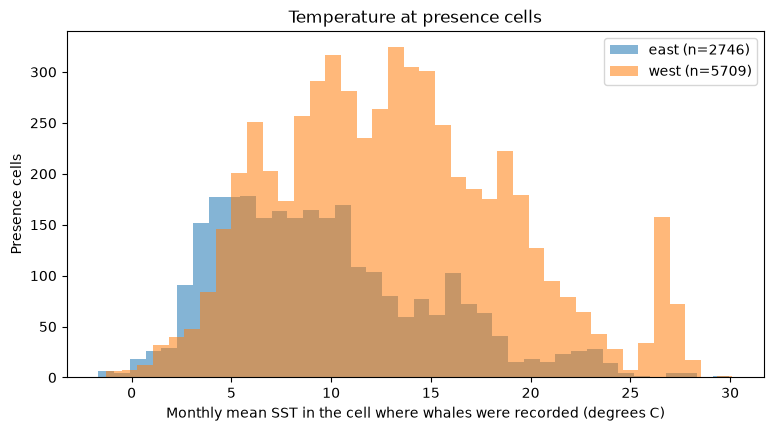


Saved: ..\data\processed\presence_with_sst_v0.csv


In [12]:
# --- Cell 8: match monthly SST and anomaly to the presence cells ---
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

OUT_DIR = Path("../data/processed") if Path("../archive").exists() else Path("data/processed")
SST_DIR = Path("../data/raw/sst_oisst") if Path("../archive").exists() else Path("data/raw/sst_oisst")

pres = pd.read_csv(OUT_DIR / "presence_cell_month_obis_v0.csv")
print("Presence rows (cell x month):", len(pres))

results, max_offset, missing_months = [], 0.0, []
for ym, grp in pres.groupby("year_month"):
    f = SST_DIR / f"oisst_{ym}.nc"
    if not f.exists():
        missing_months.append(ym)
        continue
    with xr.open_dataset(f) as d:
        sst_m = d["sst"].mean("time").load()      # monthly mean over the days we have
        anom_m = d["anom"].mean("time").load()
        n_days = d.sizes["time"]
    lat = xr.DataArray(grp["cell_center_lat"].values, dims="points")
    lon = xr.DataArray(grp["cell_center_lon"].values, dims="points")
    # how far is the SST grid point we picked from our cell centre? (should be ~0)
    off_lat = np.abs(sst_m["latitude"].sel(latitude=lat, method="nearest").values - grp["cell_center_lat"].values).max()
    off_lon = np.abs(sst_m["longitude"].sel(longitude=lon, method="nearest").values - grp["cell_center_lon"].values).max()
    max_offset = max(max_offset, float(off_lat), float(off_lon))
    out = grp.copy()
    out["sst_mean"] = sst_m.sel(latitude=lat, longitude=lon, method="nearest").values
    out["anom_mean"] = anom_m.sel(latitude=lat, longitude=lon, method="nearest").values
    out["sst_days"] = n_days
    results.append(out)

matched = pd.concat(results, ignore_index=True)
print("Rows matched:", len(matched), "| months without an SST file:", missing_months or "none")
print("Largest distance between a cell centre and the SST grid point used (degrees):", round(max_offset, 6))

n_nan = int(matched["sst_mean"].isna().sum())
print(f"\nRows with no SST value (cell falls on the land mask): {n_nan} ({n_nan / len(matched):.1%})")
print(matched.groupby("region")["sst_mean"].apply(lambda s: round(float(s.isna().mean()), 3)).rename("share_without_sst").to_string())

print("\nSST and anomaly of the presence cells (degrees C):")
print(matched[["sst_mean", "anom_mean"]].describe().round(2).to_string())
print("\nMonths with fewer SST days than a full month are flagged in sst_days. Minimum days used:", int(matched["sst_days"].min()))

fig, ax = plt.subplots(figsize=(9, 4.5))
for region, g in matched.dropna(subset=["sst_mean"]).groupby("region"):
    ax.hist(g["sst_mean"], bins=40, alpha=0.55, label=f"{region} (n={len(g)})")
ax.set_xlabel("Monthly mean SST in the cell where whales were recorded (degrees C)")
ax.set_ylabel("Presence cells")
ax.set_title("Temperature at presence cells")
ax.legend()
plt.show()

matched.to_csv(OUT_DIR / "presence_with_sst_v0.csv", index=False)
print("\nSaved:", OUT_DIR / "presence_with_sst_v0.csv")

In [13]:
# --- Cell 9: look at the cells without SST, fill coastal gaps from the nearest ocean cell (flagged) ---
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr

OUT_DIR = Path("../data/processed") if Path("../archive").exists() else Path("data/processed")
SST_DIR = Path("../data/raw/sst_oisst") if Path("../archive").exists() else Path("data/raw/sst_oisst")
MAX_CELLS = 1      # how far to look for an ocean cell (1 cell = 0.25 degrees); compare 1, 2 and 3 below
SEARCH = 3         # the largest window we test

matched = pd.read_csv(OUT_DIR / "presence_with_sst_v0.csv")
need = matched["sst_mean"].isna()
print("Rows without SST:", int(need.sum()), "of", len(matched))

# 1) Where are the rows without SST? (rounded to whole degrees)
lost = matched[need]
where = lost.groupby([lost["cell_center_lat"].round(0), lost["cell_center_lon"].round(0)]).size()
print("\nWhere the rows without SST are (lat, lon rounded to 1 degree), top 10:")
print(where.sort_values(ascending=False).head(10).to_string())

# 2) For each of them, find the nearest ocean cell inside a +-3 cell window
def nearest_valid(grid, i, j, window):
    """Nearest non-NaN cell (Euclidean, in cells) inside the window. Returns (ii, jj, chebyshev_distance) or None."""
    best, best_d = None, None
    for di in range(-window, window + 1):
        for dj in range(-window, window + 1):
            ii, jj = i + di, j + dj
            if 0 <= ii < grid.shape[0] and 0 <= jj < grid.shape[1] and not np.isnan(grid[ii, jj]):
                d = (di ** 2 + dj ** 2) ** 0.5
                if best_d is None or d < best_d:
                    best, best_d = (ii, jj, max(abs(di), abs(dj))), d
    return best

fills = {}
for ym, rows in lost.groupby("year_month"):
    with xr.open_dataset(SST_DIR / f"oisst_{ym}.nc") as d:
        sst_g = d["sst"].mean("time").load()
        anom_g = d["anom"].mean("time").load()
    i_idx = sst_g.indexes["latitude"].get_indexer(rows["cell_center_lat"].values, method="nearest")
    j_idx = sst_g.indexes["longitude"].get_indexer(rows["cell_center_lon"].values, method="nearest")
    s, a = sst_g.values, anom_g.values
    for label, i, j in zip(rows.index, i_idx, j_idx):
        hit = nearest_valid(s, i, j, SEARCH)
        if hit is not None:
            ii, jj, cheb = hit
            fills[label] = (float(s[ii, jj]), float(a[ii, jj]), cheb)

fill_table = pd.DataFrame.from_dict(fills, orient="index", columns=["sst_fill", "anom_fill", "fill_cells"])
print("\nRows that could be rescued by looking this many cells away (1 cell = 0.25 degrees):")
for r in (1, 2, 3):
    print(f"  within {r} cell(s): {int((fill_table['fill_cells'] <= r).sum())} of {int(need.sum())}")

# 3) Apply the chosen radius and flag every filled row
filled = matched.copy()
filled["sst_fill_cells"] = np.nan                       # NaN = exact cell, 1.0 = filled from a neighbour
use = fill_table[fill_table["fill_cells"] <= MAX_CELLS]
filled.loc[use.index, "sst_mean"] = use["sst_fill"]
filled.loc[use.index, "anom_mean"] = use["anom_fill"]
filled.loc[use.index, "sst_fill_cells"] = use["fill_cells"]

print(f"\nFilled with MAX_CELLS={MAX_CELLS}: {len(use)} rows | still without SST: {int(filled['sst_mean'].isna().sum())}")
print("Still without SST by region (share):")
print(filled.groupby("region")["sst_mean"].apply(lambda s: round(float(s.isna().mean()), 3)).to_string())

exact = filled[filled["sst_fill_cells"].isna()]
nb = filled[filled["sst_fill_cells"].notna()]
print("\nDo filled rows look different from exact rows? (mean sst, mean anomaly)")
print(f"  exact:  n={len(exact)}  sst={exact['sst_mean'].mean():.2f}  anom={exact['anom_mean'].mean():.2f}")
print(f"  filled: n={len(nb)}  sst={nb['sst_mean'].mean():.2f}  anom={nb['anom_mean'].mean():.2f}")

# 4) Extreme anomalies: real or suspicious?
cols = ["cell_center_lat", "cell_center_lon", "year_month", "sst_mean", "anom_mean", "sst_days"]
print("\nFive most negative anomalies:")
print(filled.nsmallest(5, "anom_mean")[cols].round(2).to_string(index=False))
print("\nFive most positive anomalies:")
print(filled.nlargest(5, "anom_mean")[cols].round(2).to_string(index=False))

filled.to_csv(OUT_DIR / "presence_with_sst_v1.csv", index=False)
print("\nSaved:", OUT_DIR / "presence_with_sst_v1.csv")

Rows without SST: 1136 of 9591

Where the rows without SST are (lat, lon rounded to 1 degree), top 10:
cell_center_lat  cell_center_lon
66.0             -18.0              180
                 -23.0               72
47.0             -53.0               65
64.0             -22.0               52
70.0              22.0               41
37.0             -76.0               32
66.0             -22.0               29
45.0             -67.0               25
65.0             -24.0               23
77.0              16.0               23

Rows that could be rescued by looking this many cells away (1 cell = 0.25 degrees):
  within 1 cell(s): 1026 of 1136
  within 2 cell(s): 1114 of 1136
  within 3 cell(s): 1130 of 1136

Filled with MAX_CELLS=1: 1026 rows | still without SST: 110
Still without SST by region (share):
region
east    0.026
west    0.003

Do filled rows look different from exact rows? (mean sst, mean anomaly)
  exact:  n=8565  sst=12.01  anom=0.63
  filled: n=1026  sst=9.47  anom=0.

Presence rows kept: 9481 of 9591 (dropped 110 without SST)

Rows by region and class:
presence  background  presence
region                        
east           25327      3460
west           22078      6021

Presence vs background: SST and anomaly (mean, std):
         sst_mean       anom_mean      
             mean   std      mean   std
presence                               
0           15.68  9.93      0.65  1.12
1           11.73  5.86      0.67  1.64


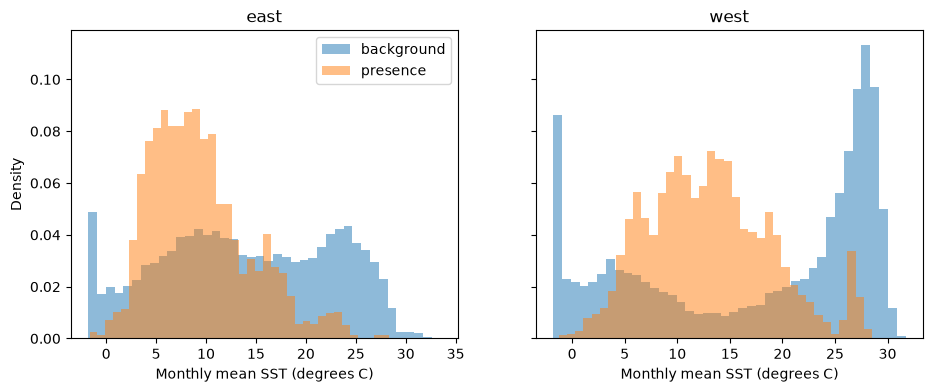


Saved: ..\data\processed\model_table_v0.csv | 56886 rows


In [14]:
# --- Cell 10: background points + model table (v0) ---
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

OUT_DIR = Path("../data/processed") if Path("../archive").exists() else Path("data/processed")
SST_DIR = Path("../data/raw/sst_oisst") if Path("../archive").exists() else Path("data/raw/sst_oisst")
K = 5        # background rows per presence row, drawn from the same month
SEED = 42    # fixed seed: the same background every time we run this cell

pres = pd.read_csv(OUT_DIR / "presence_with_sst_v1.csv")
n_before = len(pres)
pres = pres.dropna(subset=["sst_mean", "anom_mean"]).copy()
print(f"Presence rows kept: {len(pres)} of {n_before} (dropped {n_before - len(pres)} without SST)")
pres["presence"] = 1

rng = np.random.default_rng(SEED)
bg_parts = []
for ym, grp in pres.groupby("year_month"):
    n_bg = K * len(grp)
    with xr.open_dataset(SST_DIR / f"oisst_{ym}.nc") as d:
        sst_m = d["sst"].mean("time").load()
        anom_m = d["anom"].mean("time").load()
        n_days = d.sizes["time"]
    ocean = np.argwhere(~np.isnan(sst_m.values))                 # (row, col) of every ocean cell this month
    pick = ocean[rng.choice(len(ocean), size=n_bg, replace=False)]
    bg_parts.append(pd.DataFrame({
        "cell_center_lat": sst_m["latitude"].values[pick[:, 0]],
        "cell_center_lon": sst_m["longitude"].values[pick[:, 1]],
        "year_month": ym,
        "sst_mean": sst_m.values[pick[:, 0], pick[:, 1]],
        "anom_mean": anom_m.values[pick[:, 0], pick[:, 1]],
        "sst_days": n_days,
    }))
bg = pd.concat(bg_parts, ignore_index=True)
bg["presence"] = 0
bg["obs_year"] = bg["year_month"].str[:4].astype(int)
bg["obs_month"] = bg["year_month"].str[5:7].astype(int)
bg["region"] = np.where(bg["cell_center_lon"] > -35, "east", "west")
bg["sst_fill_cells"] = np.nan

keep = ["cell_center_lat", "cell_center_lon", "year_month", "obs_year", "obs_month", "region",
        "sst_mean", "anom_mean", "sst_days", "sst_fill_cells", "presence"]
table = pd.concat([pres[keep], bg[keep]], ignore_index=True)

print("\nRows by region and class:")
print(pd.crosstab(table["region"], table["presence"]).rename(columns={0: "background", 1: "presence"}).to_string())

print("\nPresence vs background: SST and anomaly (mean, std):")
print(table.groupby("presence")[["sst_mean", "anom_mean"]].agg(["mean", "std"]).round(2).to_string())

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, (region, g) in zip(axes, table.groupby("region")):
    for label, gg in g.groupby("presence"):
        ax.hist(gg["sst_mean"], bins=40, density=True, alpha=0.5, label="presence" if label == 1 else "background")
    ax.set_title(region)
    ax.set_xlabel("Monthly mean SST (degrees C)")
axes[0].set_ylabel("Density")
axes[0].legend()
plt.show()

table.to_csv(OUT_DIR / "model_table_v0.csv", index=False)
print("\nSaved:", OUT_DIR / "model_table_v0.csv", "|", len(table), "rows")

netCDF files found: ['gebco_2026_sub_ice_n80.0_s10.0_w-85.0_e40.0.nc']
Using: gebco_2026_sub_ice_n80.0_s10.0_w-85.0_e40.0.nc | 1.01 GB
<xarray.Dataset> Size: 2GB
Dimensions:    (lat: 16800, lon: 30000)
Coordinates:
  * lat        (lat) float64 134kB 10.0 10.01 10.01 10.01 ... 79.99 79.99 80.0
  * lon        (lon) float64 240kB -85.0 -84.99 -84.99 ... 39.99 39.99 40.0
Data variables:
    crs        |S1 1B ...
    elevation  (lat, lon) float32 2GB ...
Attributes: (12/37)
    comment:                         The data in the GEBCO_2026 Grid should n...
    Conventions:                     CF-1.6, ACDD-1.3
    creator_email:                   gdacc@seabed2030.org
    creator_name:                    GEBCO through the Nippon Foundation-GEBC...
    creator_type:                    International organisation
    creator_url:                     https://www.gebco.net
    ...                              ...
    project:                         Nippon Foundation - GEBCO Seabed2030 Pro...
    ref

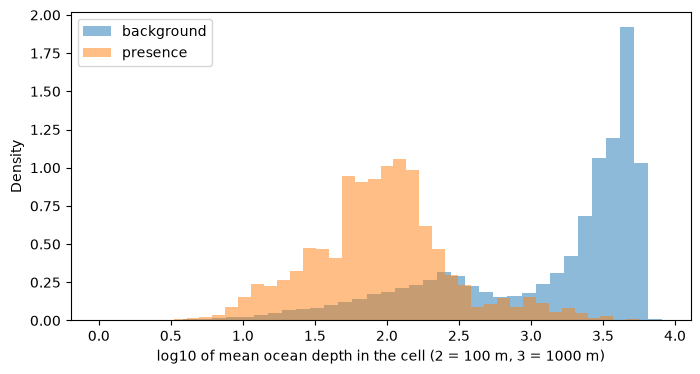


Saved: ..\data\processed\model_table_v1.csv | 56886 rows


In [15]:
# --- Cell 11: GEBCO depth features at 0.25 degrees (static: no month) ---
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

GEBCO_DIR = Path("../data/raw/gebco") if Path("../archive").exists() else Path("data/raw/gebco")
OUT_DIR = Path("../data/processed") if Path("../archive").exists() else Path("data/processed")
GRID = 0.25
CELLS = 60            # 0.25 degrees = 60 GEBCO cells of 15 arc-seconds

# 1) Find the elevation file (the TID file, if present, is skipped)
files = sorted(GEBCO_DIR.glob("*.nc"))
print("netCDF files found:", [f.name for f in files])
elev_files = [f for f in files if "tid" not in f.name.lower()]
if not elev_files:
    raise FileNotFoundError("No elevation .nc file found in " + str(GEBCO_DIR.resolve()))
GEBCO_FILE = elev_files[0]
print("Using:", GEBCO_FILE.name, f"| {GEBCO_FILE.stat().st_size / 1e9:.2f} GB")

ds = xr.open_dataset(GEBCO_FILE)
print(ds)
var_name = next(v for v in ds.data_vars if ds[v].ndim == 2)
lat_name, lon_name = ds[var_name].dims
lat = ds[lat_name].values.astype("float64")
lon = ds[lon_name].values.astype("float64")
print(f"\nVariable: {var_name} | dims: {lat_name}, {lon_name} | dtype: {ds[var_name].dtype} | shape: {ds[var_name].shape}")
print("lat:", round(lat.min(), 4), "->", round(lat.max(), 4), "| lon:", round(lon.min(), 4), "->", round(lon.max(), 4))
if lat[0] > lat[-1] or lon[0] > lon[-1]:
    raise ValueError("Latitude or longitude is in descending order. Send this output to Claude.")

# 2) Keep only complete 0.25-degree cells (60 x 60 GEBCO cells); partial cells at the edges are dropped
def complete_cells(coord):
    cell = np.floor(coord / GRID).astype(int)
    ids, first, counts = np.unique(cell, return_index=True, return_counts=True)
    keep = counts == CELLS
    return ids[keep], first[keep], int((~keep).sum())

lat_ids, lat_first, lat_dropped = complete_cells(lat)
lon_ids, lon_first, lon_dropped = complete_cells(lon)
if not (np.all(np.diff(lat_ids) == 1) and np.all(np.diff(lon_ids) == 1)):
    raise ValueError("Complete cells are not consecutive. Send this output to Claude.")
print(f"\nComplete cells: {len(lat_ids)} lat x {len(lon_ids)} lon | partial edge cells dropped: {lat_dropped} lat, {lon_dropped} lon")

# 3) Statistics per 0.25-degree cell, one latitude row of cells at a time (keeps memory small)
elev = ds[var_name]
col_slice = slice(int(lon_first[0]), int(lon_first[-1]) + CELLS)
n_lon = len(lon_ids)
lon_centres = lon_ids * GRID + GRID / 2
parts = []
for cell_id, r0 in zip(lat_ids, lat_first):
    block = elev.isel({lat_name: slice(int(r0), int(r0) + CELLS), lon_name: col_slice}).values.astype("float32")
    block = block.reshape(CELLS, n_lon, CELLS)
    ocean = block < 0                                    # negative = below sea level
    n_ocean = ocean.sum(axis=(0, 2))
    depth = np.where(ocean, -block, 0.0).astype("float64")
    s1 = depth.sum(axis=(0, 2))
    s2 = (depth ** 2).sum(axis=(0, 2))
    with np.errstate(invalid="ignore", divide="ignore"):
        mean = np.where(n_ocean > 0, s1 / n_ocean, np.nan)
        var = np.where(n_ocean > 0, s2 / n_ocean - mean ** 2, np.nan)
    parts.append(pd.DataFrame({
        "cell_center_lat": cell_id * GRID + GRID / 2,
        "cell_center_lon": lon_centres,
        "depth_mean_m": mean,
        "depth_std_m": np.sqrt(np.clip(var, 0, None)),
        "ocean_frac": n_ocean / (CELLS * CELLS),
    }))
cells = pd.concat(parts, ignore_index=True)
cells.to_csv(OUT_DIR / "gebco_cells_025.csv", index=False)
print("\nCells computed:", len(cells), "| cells with no ocean at all:", int((cells["ocean_frac"] == 0).sum()))
print(cells[["depth_mean_m", "depth_std_m", "ocean_frac"]].describe().round(1).to_string())

# 4) Add the depth features to the model table (same cell centre = same cell)
table = pd.read_csv(OUT_DIR / "model_table_v0.csv")
table["_lat"] = table["cell_center_lat"].round(3)
table["_lon"] = table["cell_center_lon"].round(3)
keys = cells.assign(_lat=cells["cell_center_lat"].round(3), _lon=cells["cell_center_lon"].round(3))
merged = table.merge(keys[["_lat", "_lon", "depth_mean_m", "depth_std_m", "ocean_frac"]], on=["_lat", "_lon"], how="left")
merged = merged.drop(columns=["_lat", "_lon"])

no_depth = merged["depth_mean_m"].isna()
print("\nModel table rows without depth (cell outside the GEBCO box or no ocean in it):")
print(no_depth.groupby(merged["presence"]).sum().rename({0: "background", 1: "presence"}).to_string())

print("\nMean ocean depth of the cell (m): presence vs background")
print(merged.groupby("presence")["depth_mean_m"].describe(percentiles=[.25, .5, .75]).round(0).to_string())
print("\nShare of ocean inside the cell (1 = all ocean): presence vs background")
print(merged.groupby("presence")["ocean_frac"].describe(percentiles=[.25, .5, .75]).round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
for label, g in merged.dropna(subset=["depth_mean_m"]).groupby("presence"):
    ax.hist(np.log10(g["depth_mean_m"].clip(lower=1)), bins=40, density=True, alpha=0.5,
            label="presence" if label == 1 else "background")
ax.set_xlabel("log10 of mean ocean depth in the cell (2 = 100 m, 3 = 1000 m)")
ax.set_ylabel("Density")
ax.legend()
plt.show()

merged.to_csv(OUT_DIR / "model_table_v1.csv", index=False)
print("\nSaved:", OUT_DIR / "model_table_v1.csv", "|", len(merged), "rows")

Rows kept: 56816 of 56886 | presence: 9481 | background: 47335

=== Seasonal baseline, trained on the past only, tested on each later year ===
 test_year subset  train_presences  test_presences   AUC  top_area_share  presences_inside
      2020    all             4570             387 0.961           0.100             0.933
      2020   east             4570             118 0.914           0.100             0.780
      2020   west             4570             269 0.981           0.101             0.981
      2021    all             4957             539 0.972           0.100             0.957
      2021   east             4957             152 0.949           0.101             0.888
      2021   west             4957             387 0.980           0.100             0.977
      2022    all             5496             709 0.970           0.100             0.948
      2022   east             5496             246 0.958           0.100             0.911
      2022   west             5496    

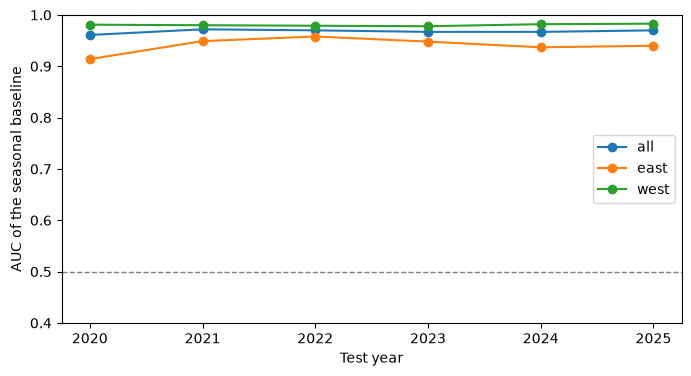


Saved: ..\data\processed\baseline_results_v0.csv


In [16]:
# --- Cell 12: seasonal baseline + rolling-origin evaluation ---
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT_DIR = Path("../data/processed") if Path("../archive").exists() else Path("data/processed")
SIGMA_KM = 100.0                        # how far a past sighting still "counts" for a cell (kernel width)
TEST_YEARS = list(range(2020, 2026))    # 2026 is a partial year, left out for now

table = pd.read_csv(OUT_DIR / "model_table_v1.csv")
n0 = len(table)
table = table.dropna(subset=["depth_mean_m"]).copy()      # drops the few background rows without depth
print(f"Rows kept: {len(table)} of {n0} | presence: {int(table['presence'].sum())} | background: {int((table['presence'] == 0).sum())}")

def baseline_scores(train_pres, test_rows, sigma_km):
    """Seasonal baseline: for each test row, add up Gaussian weights of past presences from the SAME calendar month.
    The closer and the more numerous the past sightings, the higher the score. No environment is used."""
    scores = np.zeros(len(test_rows))
    lat_all = test_rows["cell_center_lat"].values
    lon_all = test_rows["cell_center_lon"].values
    for month, idx in test_rows.groupby("obs_month").indices.items():
        past = train_pres[train_pres["obs_month"] == month]
        if len(past) == 0:
            continue
        lat_t, lon_t = lat_all[idx][:, None], lon_all[idx][:, None]
        lat_p, lon_p = past["cell_center_lat"].values[None, :], past["cell_center_lon"].values[None, :]
        dx = (lon_t - lon_p) * 111.32 * np.cos(np.radians((lat_t + lat_p) / 2))
        dy = (lat_t - lat_p) * 110.57
        scores[idx] = np.exp(-(dx ** 2 + dy ** 2) / (2 * sigma_km ** 2)).sum(axis=1)
    return scores

def auc(scores, labels):
    """Chance that a random presence scores higher than a random background cell (0.5 = coin flip)."""
    ranks = pd.Series(scores).rank(method="average").values
    n_pos = int(labels.sum())
    n_neg = len(labels) - n_pos
    return (ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def top_area_capture(scores, labels, area=0.10):
    """Take the highest-scoring cells covering about `area` of the background (= of the ocean).
    Returns (share of background actually inside, share of presences inside)."""
    bg, pr = scores[labels == 0], scores[labels == 1]
    thr = np.quantile(bg, 1 - area)
    inside = (lambda s: s > 0) if thr <= 0 else (lambda s: s >= thr)
    return float(inside(bg).mean()), float(inside(pr).mean())

rows = []
for year in TEST_YEARS:
    train = table[(table["obs_year"] < year) & (table["presence"] == 1)]      # only the past
    test = table[table["obs_year"] == year].reset_index(drop=True)
    scores = baseline_scores(train, test, SIGMA_KM)
    labels = test["presence"].values
    for name, mask in [("all", np.ones(len(test), bool)),
                       ("east", (test["region"] == "east").values),
                       ("west", (test["region"] == "west").values)]:
        s, y = scores[mask], labels[mask]
        if y.sum() == 0 or (y == 0).sum() == 0:
            continue
        area_share, capture = top_area_capture(s, y)
        rows.append({"test_year": year, "subset": name, "train_presences": len(train),
                     "test_presences": int(y.sum()), "AUC": round(auc(s, y), 3),
                     "top_area_share": round(area_share, 3), "presences_inside": round(capture, 3)})

results = pd.DataFrame(rows)
print("\n=== Seasonal baseline, trained on the past only, tested on each later year ===")
print(results.to_string(index=False))
print("\nAverage over the test years:")
print(results.groupby("subset")[["AUC", "top_area_share", "presences_inside"]].mean().round(3).to_string())
print("\nReference: a random map has AUC 0.5 and captures as many presences as the area share it covers.")

fig, ax = plt.subplots(figsize=(8, 4))
for name, g in results.groupby("subset"):
    ax.plot(g["test_year"], g["AUC"], marker="o", label=name)
ax.axhline(0.5, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Test year")
ax.set_ylabel("AUC of the seasonal baseline")
ax.set_ylim(0.4, 1.0)
ax.legend()
plt.show()

results.to_csv(OUT_DIR / "baseline_results_v0.csv", index=False)
print("\nSaved:", OUT_DIR / "baseline_results_v0.csv")

In [17]:
Path("../docs/figures").mkdir(parents=True, exist_ok=True)
fig.savefig("../docs/figures/baseline_auc_by_year.png", dpi=200, bbox_inches="tight")

Climatology built. Most years averaged into one cell and month: 10
Rows: 56816 (dropped 70 without depth) | climatology taken from a neighbour: 1026 | still missing: 0

Our own anomaly vs the built-in OISST anomaly (degrees C):
         anom_own                    anom_mean                    
             mean   std   min    max      mean   std    min    max
presence                                                          
0            0.17  0.85 -7.99  10.42      0.65  1.12  -8.76  11.33
1            0.08  0.95 -4.97   6.01      0.67  1.64 -11.08   7.91
Correlation between the two anomalies: 0.686

Five most negative own anomalies:
 cell_center_lat  cell_center_lon year_month  sst_mean  clim_sst  anom_own
           69.88           -52.38    2021-07     -0.92      7.07     -7.99
           38.38           -65.12    2025-04     11.34     19.07     -7.73
           51.62           -79.88    2020-08      1.69      8.76     -7.07
           38.12           -69.62    2025-04     12.41   

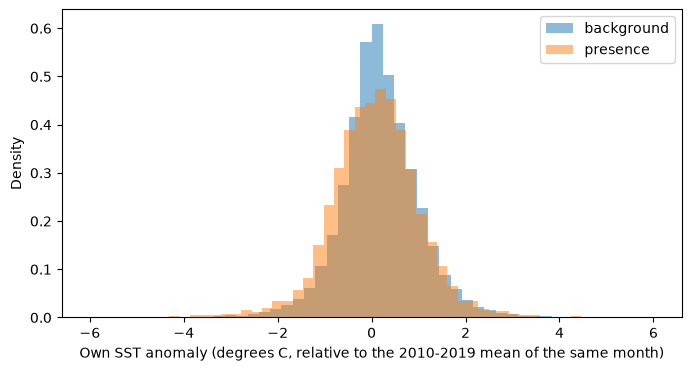


Saved: ..\data\processed\model_table_v2.csv | 56816 rows


In [18]:
# --- Cell 13: our own SST anomaly (2010-2019 climatology) and the final feature table ---
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

OUT_DIR = Path("../data/processed") if Path("../archive").exists() else Path("data/processed")
SST_DIR = Path("../data/raw/sst_oisst") if Path("../archive").exists() else Path("data/raw/sst_oisst")
CLIM_YEARS = range(2010, 2020)      # reference period; every test year is 2020 or later, so nothing leaks

# 1) Climatology: mean SST of each calendar month over 2010-2019, for every grid cell
sum_g = cnt_g = None
for f in sorted(SST_DIR.glob("oisst_*.nc")):
    year, month = int(f.stem[6:10]), int(f.stem[11:13])
    if year not in CLIM_YEARS:
        continue
    with xr.open_dataset(f) as d:
        grid = d["sst"].mean("time").load()
    if sum_g is None:
        lat_vals, lon_vals = grid["latitude"].values, grid["longitude"].values
        sum_g = np.zeros((12, len(lat_vals), len(lon_vals)))
        cnt_g = np.zeros_like(sum_g)
    v = grid.values
    ok = ~np.isnan(v)
    sum_g[month - 1][ok] += v[ok]
    cnt_g[month - 1][ok] += 1
clim = np.where(cnt_g > 0, sum_g / np.where(cnt_g > 0, cnt_g, 1), np.nan)
print("Climatology built. Most years averaged into one cell and month:", int(cnt_g.max()))

# 2) Look up the climatology for every row of the model table
table = pd.read_csv(OUT_DIR / "model_table_v1.csv")
n0 = len(table)
table = table.dropna(subset=["depth_mean_m"]).reset_index(drop=True)
lat_idx = pd.Index(lat_vals).get_indexer(table["cell_center_lat"].values, method="nearest")
lon_idx = pd.Index(lon_vals).get_indexer(table["cell_center_lon"].values, method="nearest")
month_idx = table["obs_month"].values.astype(int) - 1
clim_val = clim[month_idx, lat_idx, lon_idx]

# Rows whose SST was taken from a neighbouring cell (coastal fill) get the neighbour's climatology too
def nearest_valid(grid, i, j, window):
    best, best_d = None, None
    for di in range(-window, window + 1):
        for dj in range(-window, window + 1):
            ii, jj = i + di, j + dj
            if 0 <= ii < grid.shape[0] and 0 <= jj < grid.shape[1] and not np.isnan(grid[ii, jj]):
                d = (di ** 2 + dj ** 2) ** 0.5
                if best_d is None or d < best_d:
                    best, best_d = (ii, jj), d
    return best

missing = np.where(np.isnan(clim_val))[0]
for r in missing:
    hit = nearest_valid(clim[month_idx[r]], lat_idx[r], lon_idx[r], 1)
    if hit is not None:
        clim_val[r] = clim[month_idx[r], hit[0], hit[1]]
print(f"Rows: {len(table)} (dropped {n0 - len(table)} without depth) | climatology taken from a neighbour: {len(missing)} | still missing: {int(np.isnan(clim_val).sum())}")

table["clim_sst"] = clim_val
table["anom_own"] = table["sst_mean"] - table["clim_sst"]

# 3) Model features
table["depth_log"] = np.log10(table["depth_mean_m"].clip(lower=1))
table["depth_std_log"] = np.log10(1 + table["depth_std_m"])
table["month_sin"] = np.sin(2 * np.pi * table["obs_month"] / 12)
table["month_cos"] = np.cos(2 * np.pi * table["obs_month"] / 12)

print("\nOur own anomaly vs the built-in OISST anomaly (degrees C):")
print(table.groupby("presence")[["anom_own", "anom_mean"]].agg(["mean", "std", "min", "max"]).round(2).to_string())
print("Correlation between the two anomalies:", round(float(table[["anom_own", "anom_mean"]].corr().iloc[0, 1]), 3))

cols = ["cell_center_lat", "cell_center_lon", "year_month", "sst_mean", "clim_sst", "anom_own"]
print("\nFive most negative own anomalies:")
print(table.nsmallest(5, "anom_own")[cols].round(2).to_string(index=False))
print("\nFive most positive own anomalies:")
print(table.nlargest(5, "anom_own")[cols].round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4))
for label, g in table.dropna(subset=["anom_own"]).groupby("presence"):
    ax.hist(g["anom_own"].clip(-6, 6), bins=50, density=True, alpha=0.5, label="presence" if label == 1 else "background")
ax.set_xlabel("Own SST anomaly (degrees C, relative to the 2010-2019 mean of the same month)")
ax.set_ylabel("Density")
ax.legend()
plt.show()

table.to_csv(OUT_DIR / "model_table_v2.csv", index=False)
print("\nSaved:", OUT_DIR / "model_table_v2.csv", "|", len(table), "rows")

Rows: 54245 | presence: 9052 | background: 45193

=== Average over the test years 2020-2025 ===
                               AUC  presences_inside
subset model                                        
all    baseline              0.968             0.944
       baseline+environment  0.987             0.982
       environment           0.966             0.933
east   baseline              0.941             0.864
       baseline+environment  0.982             0.966
       environment           0.965             0.930
west   baseline              0.980             0.981
       baseline+environment  0.988             0.994
       environment           0.975             0.975

Gain over the seasonal baseline (average over the test years):
model   environment minus baseline  baseline+environment minus baseline
subset                                                                 
all                         -0.002                                0.019
east                         0.024       

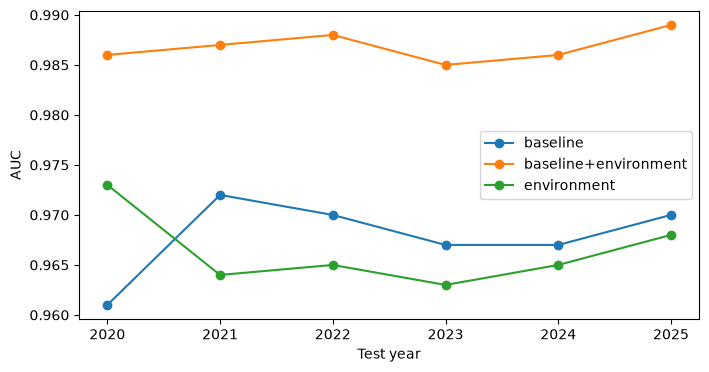


Saved: ..\data\processed\model_results_v0.csv


In [19]:
# --- Cell 14: environment model vs seasonal baseline (rolling-origin), transfer test, feature importance ---
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try:
    from sklearn.ensemble import HistGradientBoostingClassifier
except ImportError:
    raise ImportError("scikit-learn is missing. In the terminal (venv active) run: pip install scikit-learn")

OUT_DIR = Path("../data/processed") if Path("../archive").exists() else Path("data/processed")
SIGMA_KM = 100.0
TEST_YEARS = list(range(2020, 2026))
ENV = ["sst_mean", "anom_own", "depth_log", "depth_std_log", "ocean_frac", "month_sin", "month_cos"]
COMBINED = ENV + ["base_log"]

table = pd.read_csv(OUT_DIR / "model_table_v2.csv")
table = table[table["obs_year"] <= 2025].reset_index(drop=True)      # 2026 is a partial year
print("Rows:", len(table), "| presence:", int(table["presence"].sum()), "| background:", int((table["presence"] == 0).sum()))

def baseline_scores(train_pres, test_rows, sigma_km):
    scores = np.zeros(len(test_rows))
    lat_all, lon_all = test_rows["cell_center_lat"].values, test_rows["cell_center_lon"].values
    for month, idx in test_rows.groupby("obs_month").indices.items():
        past = train_pres[train_pres["obs_month"] == month]
        if len(past) == 0:
            continue
        lat_t, lon_t = lat_all[idx][:, None], lon_all[idx][:, None]
        lat_p, lon_p = past["cell_center_lat"].values[None, :], past["cell_center_lon"].values[None, :]
        dx = (lon_t - lon_p) * 111.32 * np.cos(np.radians((lat_t + lat_p) / 2))
        dy = (lat_t - lat_p) * 110.57
        scores[idx] = np.exp(-(dx ** 2 + dy ** 2) / (2 * sigma_km ** 2)).sum(axis=1)
    return scores

def auc(scores, labels):
    ranks = pd.Series(scores).rank(method="average").values
    n_pos = int(labels.sum()); n_neg = len(labels) - n_pos
    return (ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)

def top_area_capture(scores, labels, area=0.10):
    bg, pr = scores[labels == 0], scores[labels == 1]
    thr = np.quantile(bg, 1 - area)
    inside = (lambda s: s > 0) if thr <= 0 else (lambda s: s >= thr)
    return float(inside(bg).mean()), float(inside(pr).mean())

def make_model():
    return HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=200,
                                          l2_regularization=1.0, early_stopping=False, random_state=42)

# 1) "Past-only" baseline score for every row: rows of year y are scored with presences from years < y.
#    The same feature is used for training rows, so no row ever sees its own year or the future.
table["base_score"] = np.nan
for y in sorted(table["obs_year"].unique()):
    past = table[(table["obs_year"] < y) & (table["presence"] == 1)]
    if len(past) == 0:
        continue
    rows_y = table.index[table["obs_year"] == y]
    table.loc[rows_y, "base_score"] = baseline_scores(past, table.loc[rows_y].reset_index(drop=True), SIGMA_KM)
table["base_log"] = np.log1p(table["base_score"])

# 2) Rolling-origin test: train on earlier years, test on the next year
subsets = {"all": None, "east": "east", "west": "west"}
rows, last = [], {}
for year in TEST_YEARS:
    train = table[table["obs_year"] < year]
    test = table[table["obs_year"] == year].reset_index(drop=True)
    labels = test["presence"].values
    scores = {"baseline": test["base_score"].values}
    for name, cols in [("environment", ENV), ("baseline+environment", COMBINED)]:
        model = make_model().fit(train[cols], train["presence"])
        scores[name] = model.predict_proba(test[cols])[:, 1]
        last[name] = (model, cols)
    last["test"] = test
    for model_name, s_all in scores.items():
        for sub, region in subsets.items():
            mask = np.ones(len(test), bool) if region is None else (test["region"] == region).values
            s, y = s_all[mask], labels[mask]
            if y.sum() == 0 or (y == 0).sum() == 0:      # nothing to evaluate in this subset/year
                continue
            area_share, capture = top_area_capture(s, y)
            rows.append({"test_year": year, "subset": sub, "model": model_name,
                         "AUC": round(auc(s, y), 3), "top_area_share": round(area_share, 3), "presences_inside": round(capture, 3)})
res = pd.DataFrame(rows)
print("\n=== Average over the test years 2020-2025 ===")
summary = res.groupby(["subset", "model"])[["AUC", "presences_inside"]].mean().round(3)
print(summary.to_string())
print("\nGain over the seasonal baseline (average over the test years):")
piv = res.pivot_table(index=["subset", "test_year"], columns="model", values="AUC").reset_index()
for m in ["environment", "baseline+environment"]:
    piv[m + " minus baseline"] = (piv[m] - piv["baseline"]).round(3)
print(piv.groupby("subset")[["environment minus baseline", "baseline+environment minus baseline"]].mean().round(3).to_string())
print("\nAUC per year (all regions):")
print(res[res["subset"] == "all"].pivot(index="test_year", columns="model", values="AUC").to_string())

# 3) Transfer test: train in one region (years <= 2019), test in the other (2020-2025)
print("\n=== Transfer test: train in one region, test in the other ===")
tr_rows = []
for src, dst in [("west", "east"), ("east", "west")]:
    train = table[(table["region"] == src) & (table["obs_year"] <= 2019)]
    test = table[(table["region"] == dst) & (table["obs_year"] >= 2020)].reset_index(drop=True)
    labels = test["presence"].values
    if len(train) == 0 or train["presence"].nunique() < 2 or labels.sum() == 0 or (labels == 0).sum() == 0:
        print(f"  (skipped {src} -> {dst}: not enough presences or background)")
        continue
    s_env = make_model().fit(train[ENV], train["presence"]).predict_proba(test[ENV])[:, 1]
    s_base = baseline_scores(train[train["presence"] == 1], test, SIGMA_KM)
    for name, s in [("environment", s_env), ("seasonal baseline", s_base)]:
        a_share, cap = top_area_capture(s, labels)
        tr_rows.append({"train_in": src, "test_in": dst, "model": name, "AUC": round(auc(s, labels), 3), "presences_inside": round(cap, 3)})
print(pd.DataFrame(tr_rows).to_string(index=False))

# 4) Which features matter? Shuffle one feature at a time in the last test year and see how much the AUC drops
rng = np.random.default_rng(0)
test = last["test"]
labels = test["presence"].values
for name in ["environment", "baseline+environment"]:
    model, cols = last[name]
    base_auc = auc(model.predict_proba(test[cols])[:, 1], labels)
    drops = {}
    for c in cols:
        vals = []
        for _ in range(5):
            shuffled = test[cols].copy()
            shuffled[c] = rng.permutation(shuffled[c].values)
            vals.append(base_auc - auc(model.predict_proba(shuffled)[:, 1], labels))
        drops[c] = round(float(np.mean(vals)), 3)
    print(f"\nAUC drop when a feature is shuffled (model: {name}, test year 2025, full AUC {base_auc:.3f}):")
    print(pd.Series(drops).sort_values(ascending=False).to_string())

fig, ax = plt.subplots(figsize=(8, 4))
for name, g in res[res["subset"] == "all"].groupby("model"):
    ax.plot(g["test_year"], g["AUC"], marker="o", label=name)
ax.set_xlabel("Test year")
ax.set_ylabel("AUC")
ax.legend()
plt.show()

res.to_csv(OUT_DIR / "model_results_v0.csv", index=False)
print("\nSaved:", OUT_DIR / "model_results_v0.csv")

Share of rows at depth <= 500 m:  presence 0.93 | background 0.27
-> If presences are mostly shallow but background is mostly deep, depth alone separates them. The shelf test removes that shortcut.

=== Average over the test years (AUC / share of presences inside the top 10% area) ===
                                                       AUC  presences_inside
subset         model                                                        
all depths     baseline                              0.968             0.944
               baseline+environment                  0.987             0.982
               baseline+environment (shelf-trained)  0.985             0.977
               depth only                            0.943             0.811
               environment                           0.966             0.933
               environment (shelf-trained)           0.957             0.898
shelf <= 500 m baseline                              0.929             0.767
               baseli

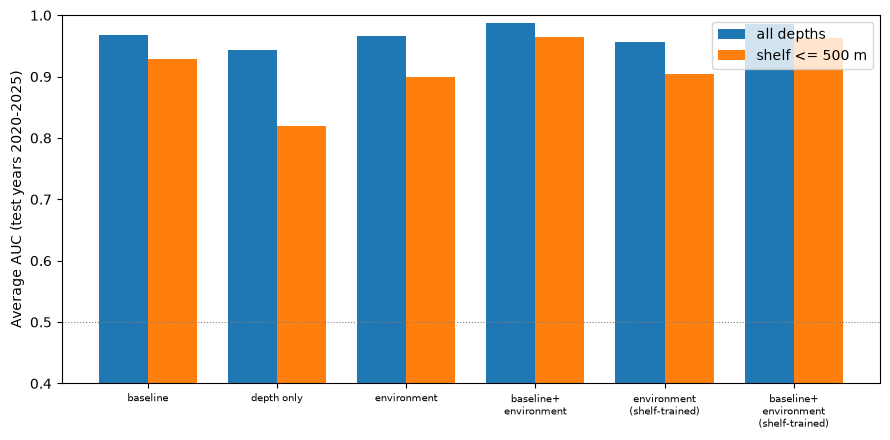


Saved: ..\data\processed\model_results_hard_v0.csv and ..\docs\figures\hard_test_shelf_auc.png


In [20]:
# --- Cell 15: harder test. Is the model still good when depth cannot do the easy work? ---
# Run this in the SAME notebook session right after Cell 14 (it reuses `table`, `ENV`, `COMBINED`,
# `make_model`, `auc`, `top_area_capture`, `TEST_YEARS`, `OUT_DIR`).
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FIG_DIR = Path("../docs/figures") if Path("../archive").exists() else Path("docs/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)
SHELF_M = 500                       # "shelf and upper slope": mean cell depth <= 500 m
DEPTH_ONLY = ["depth_log", "depth_std_log", "ocean_frac"]

is_shelf = (table["depth_mean_m"] <= SHELF_M)
print(f"Share of rows at depth <= {SHELF_M} m:  presence {is_shelf[table.presence == 1].mean():.2f} | background {is_shelf[table.presence == 0].mean():.2f}")
print("-> If presences are mostly shallow but background is mostly deep, depth alone separates them. The shelf test removes that shortcut.\n")

MODELS = {                                    # name: (feature list, train only on shelf rows?)
    "baseline": (None, False),
    "depth only": (DEPTH_ONLY, False),
    "environment": (ENV, False),
    "baseline+environment": (COMBINED, False),
    "environment (shelf-trained)": (ENV, True),
    "baseline+environment (shelf-trained)": (COMBINED, True),
}
rows = []
for year in TEST_YEARS:
    tr_all = table[table["obs_year"] < year]
    tr_shelf = tr_all[tr_all["depth_mean_m"] <= SHELF_M]
    test = table[table["obs_year"] == year].reset_index(drop=True)
    shelf_mask = (test["depth_mean_m"] <= SHELF_M).values
    for name, (cols, shelf_only) in MODELS.items():
        if cols is None:
            s_all = test["base_score"].values
        else:
            train = tr_shelf if shelf_only else tr_all
            if train["presence"].nunique() < 2:
                continue
            s_all = make_model().fit(train[cols], train["presence"]).predict_proba(test[cols])[:, 1]
        for subset, mask in [("all depths", np.ones(len(test), bool)), (f"shelf <= {SHELF_M} m", shelf_mask)]:
            s, y = s_all[mask], test["presence"].values[mask]
            if y.sum() == 0 or (y == 0).sum() == 0:
                continue
            _, capture = top_area_capture(s, y)
            rows.append({"test_year": year, "subset": subset, "model": name,
                         "AUC": round(auc(s, y), 3), "presences_inside": round(capture, 3),
                         "n_presence": int(y.sum()), "n_background": int((y == 0).sum())})
res2 = pd.DataFrame(rows)

print("=== Average over the test years (AUC / share of presences inside the top 10% area) ===")
summ = res2.groupby(["subset", "model"])[["AUC", "presences_inside"]].mean().round(3)
print(summ.to_string())
print("\nPresences and background points in the test sets (average per year):")
print(res2.groupby("subset")[["n_presence", "n_background"]].mean().round(0).to_string())

print("\nShelf-only AUC per year:")
shelf_name = f"shelf <= {SHELF_M} m"
print(res2[res2["subset"] == shelf_name].pivot(index="test_year", columns="model", values="AUC").to_string())

piv = res2[res2["subset"] == shelf_name].pivot(index="test_year", columns="model", values="AUC")
print("\nOn the shelf, gain over the seasonal baseline (average of the test years):")
for m in piv.columns:
    if m != "baseline":
        print(f"  {m:40s} {float((piv[m] - piv['baseline']).mean()):+.3f}")

fig, ax = plt.subplots(figsize=(9, 4.5))
order = list(MODELS)
width = 0.38
for k, (subset, g) in enumerate(res2.groupby("subset")):
    vals = g.groupby("model")["AUC"].mean().reindex(order)
    ax.bar(np.arange(len(order)) + (k - 0.5) * width, vals.values, width, label=subset)
ax.set_xticks(np.arange(len(order)))
ax.set_xticklabels([o.replace("+", "+\n").replace(" (", "\n(") for o in order], fontsize=7)
ax.set_ylabel("Average AUC (test years 2020-2025)")
ax.set_ylim(0.4, 1.0)
ax.axhline(0.5, color="grey", lw=0.8, ls=":")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "hard_test_shelf_auc.png", dpi=200)
plt.show()

res2.to_csv(OUT_DIR / "model_results_hard_v0.csv", index=False)
print("\nSaved:", OUT_DIR / "model_results_hard_v0.csv", "and", FIG_DIR / "hard_test_shelf_auc.png")

In [22]:
# --- Cell 16: sensitivity tests. Do the conclusions survive reasonable changes to our choices? ---
# Run in the SAME session after Cells 14 and 15 (reuses table, ENV, COMBINED, make_model, auc,
# top_area_capture, baseline_scores, TEST_YEARS, SHELF_M, OUT_DIR).
import numpy as np
import pandas as pd

def past_only_base(df, sigma_km):
    """Seasonal baseline score for every row, using only presences from earlier years."""
    out = pd.Series(np.nan, index=df.index)
    for y in sorted(df["obs_year"].unique()):
        past = df[(df["obs_year"] < y) & (df["presence"] == 1)]
        if len(past) == 0:
            continue
        idx = df.index[df["obs_year"] == y]
        out.loc[idx] = baseline_scores(past, df.loc[idx].reset_index(drop=True), sigma_km)
    return np.log1p(out)

def evaluate(df, base_col="base_log", bg_per_presence=None, exclude_filled=None, sigma_label=""):
    """Rolling-origin AUC for baseline and baseline+environment, on all depths and on the shelf."""
    cols = ENV + [base_col]
    rows = []
    for year in TEST_YEARS:
        train = df[df["obs_year"] < year]
        if bg_per_presence is not None:                  # shrink only the TRAINING background
            pres = train[train["presence"] == 1]
            bg = train[train["presence"] == 0]
            n = min(len(bg), int(bg_per_presence * len(pres)))
            train = pd.concat([pres, bg.sample(n=n, random_state=1)])
        test = df[df["obs_year"] == year]
        if exclude_filled is not None:
            test = test[~exclude_filled.loc[test.index]]
        test = test.reset_index(drop=True)
        s_model = make_model().fit(train[cols], train["presence"]).predict_proba(test[cols])[:, 1]
        for name, s_all in [("baseline", np.expm1(test[base_col].values)), ("baseline+environment", s_model)]:
            for subset, mask in [("all depths", np.ones(len(test), bool)), ("shelf", (test["depth_mean_m"] <= SHELF_M).values)]:
                s, y = s_all[mask], test["presence"].values[mask]
                if y.sum() == 0 or (y == 0).sum() == 0:
                    continue
                rows.append({"model": name, "subset": subset, "AUC": auc(s, y)})
    r = pd.DataFrame(rows).groupby(["subset", "model"])["AUC"].mean().unstack()
    r["gain"] = r["baseline+environment"] - r["baseline"]
    return r.round(3)

out = []

# A) Kernel width of the seasonal baseline
print("=== A) Baseline kernel width (sigma) ===")
for sigma in [25, 50, 100, 200]:
    d = table.copy()
    d["base_log"] = past_only_base(d, sigma)
    r = evaluate(d); r.insert(0, "test", f"sigma {sigma} km")
    out.append(r.reset_index()); print(f"\nsigma = {sigma} km\n", r.drop(columns="test").to_string())

# B) How many background points per presence in TRAINING (testing always uses all of them)
print("\n=== B) Background points per presence in training ===")
for ratio in [1, 2, 5]:
    r = evaluate(table, bg_per_presence=ratio); r.insert(0, "test", f"train background {ratio}:1")
    out.append(r.reset_index()); print(f"\n{ratio} background per presence\n", r.drop(columns="test").to_string())

# C) Rows whose SST was filled from a neighbouring cell (coastal fill)
fill_cols = [c for c in table.columns if "fill" in c.lower()]
print("\n=== C) Coastal fill ===")
if fill_cols:
    fc = fill_cols[0]
    filled = table[fc].fillna(0).astype(float) > 0
    print(f"Column used: {fc} | rows with filled SST: {int(filled.sum())} ({filled.mean():.1%}); presences among them: {int(filled[table.presence == 1].sum())}")
    r = evaluate(table, exclude_filled=filled); r.insert(0, "test", "test without filled rows")
    out.append(r.reset_index()); print("\nTest sets without filled-SST rows\n", r.drop(columns="test").to_string())
else:
    print("No column with 'fill' in its name found. Columns:", list(table.columns))

res3 = pd.concat(out, ignore_index=True)
res3.to_csv(OUT_DIR / "sensitivity_results_v0.csv", index=False)
print("\n=== Summary: gain of baseline+environment over baseline (AUC) ===")
print(res3.pivot(index="test", columns="subset", values="gain").to_string())
print("\nSaved:", OUT_DIR / "sensitivity_results_v0.csv")

=== A) Baseline kernel width (sigma) ===

sigma = 25 km
 model       baseline  baseline+environment   gain
subset                                           
all depths     0.975                 0.988  0.013
shelf          0.947                 0.967  0.021

sigma = 50 km
 model       baseline  baseline+environment   gain
subset                                           
all depths     0.973                 0.987  0.014
shelf          0.942                 0.966  0.025

sigma = 100 km
 model       baseline  baseline+environment   gain
subset                                           
all depths     0.968                 0.987  0.019
shelf          0.928                 0.964  0.035

sigma = 200 km
 model       baseline  baseline+environment   gain
subset                                           
all depths     0.953                 0.985  0.032
shelf          0.905                 0.958  0.053

=== B) Background points per presence in training ===

1 background per presence
 model     

In [23]:
import pandas as pd
from pathlib import Path
g = pd.read_csv(OUT_DIR / "gebco_cells_025.csv")
print(g.columns.tolist())
print(g.shape)
print(g.head(3).to_string())
print(sorted(p.name for p in Path("../data/raw/sst_oisst").glob("oisst_2025-*.nc"))[:3])

['cell_center_lat', 'cell_center_lon', 'depth_mean_m', 'depth_std_m', 'ocean_frac']
(140000, 5)
   cell_center_lat  cell_center_lon  depth_mean_m  depth_std_m  ocean_frac
0           10.125          -84.875      12.51895     5.156339    0.095278
1           10.125          -84.625           NaN          NaN    0.000000
2           10.125          -84.375           NaN          NaN    0.000000
['oisst_2025-01.nc', 'oisst_2025-02.nc', 'oisst_2025-03.nc']


Ocean cells in the map grid: 92883

=== Map for 2025-01 (trained on years < 2025) ===
Cells with a complete feature set: 87527 | dropped: 5356
Recorded presences in that month: 42 | inside the top 10% of cells: 1.00 | inside the top 25%: 1.00 | median rank: 0.99

=== Map for 2025-07 (trained on years < 2025) ===
Cells with a complete feature set: 87527 | dropped: 5356
Recorded presences in that month: 194 | inside the top 10% of cells: 0.98 | inside the top 25%: 1.00 | median rank: 0.99


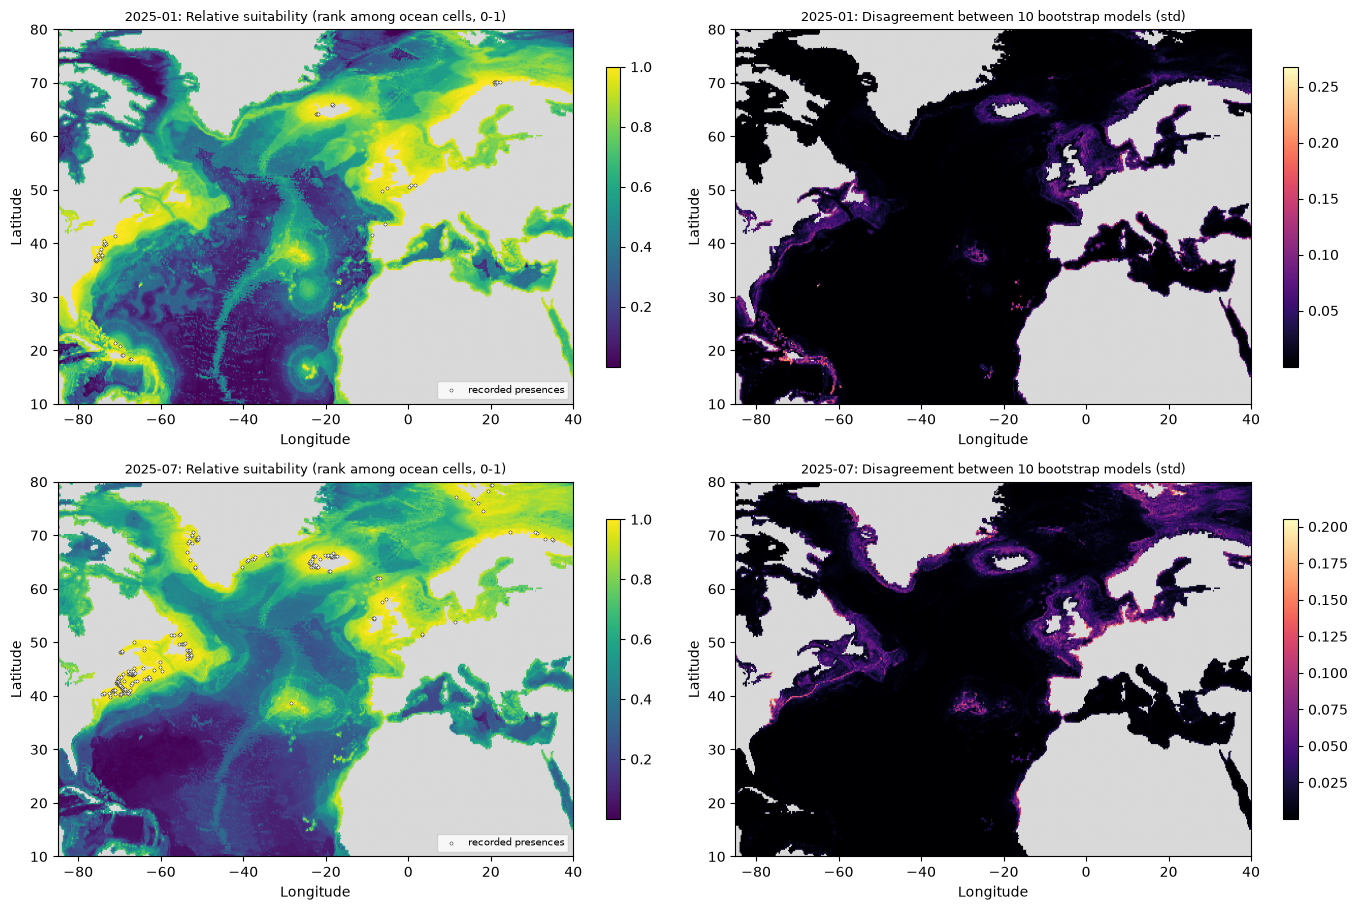


Saved figure: ..\docs\figures\suitability_maps_hindcast.png | CSVs: map_YYYY_MM.csv in ..\data\processed


In [24]:
# --- Cell 17: monthly relative-suitability maps (hindcast) with an uncertainty layer ---
# Run in the SAME session after Cells 14-16 (reuses table, COMBINED, make_model, SIGMA_KM, OUT_DIR, FIG_DIR).
# Hindcast logic: train only on years BEFORE the map year, predict the map month, then overlay the
# presences that were really recorded in that month so we can see if the map makes sense.
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt

MAP_MONTHS = [(2025, 1), (2025, 7)]      # (year, month): January = breeding season, July = feeding season
N_BOOT = 10                              # bootstrap models used for the uncertainty layer
CLIM_YEARS = range(2010, 2020)
SST_DIR = Path("../data/raw/sst_oisst") if Path("../archive").exists() else Path("data/raw/sst_oisst")

grid = pd.read_csv(OUT_DIR / "gebco_cells_025.csv")
grid = grid[grid["depth_mean_m"].notna()].reset_index(drop=True)      # ocean cells with a depth value
grid["depth_log"] = np.log10(grid["depth_mean_m"].clip(lower=1))
grid["depth_std_log"] = np.log10(1 + grid["depth_std_m"])
print("Ocean cells in the map grid:", len(grid))

def fill_missing(field, lat_i, lon_i):
    """Values for the grid cells; where the field is NaN take the nearest valid neighbour (window 1)."""
    vals = field[lat_i, lon_i].copy()
    for r in np.where(np.isnan(vals))[0]:
        best, best_d = np.nan, None
        for di in (-1, 0, 1):
            for dj in (-1, 0, 1):
                ii, jj = lat_i[r] + di, lon_i[r] + dj
                if 0 <= ii < field.shape[0] and 0 <= jj < field.shape[1] and not np.isnan(field[ii, jj]):
                    d = (di * di + dj * dj) ** 0.5
                    if best_d is None or d < best_d:
                        best, best_d = field[ii, jj], d
        vals[r] = best
    return vals

def month_mean_sst(path):
    with xr.open_dataset(path) as d:
        g = d["sst"].mean("time").load()
    return g.values, g["latitude"].values, g["longitude"].values

lat_all = np.sort(grid["cell_center_lat"].unique()); lon_all = np.sort(grid["cell_center_lon"].unique())
extent = [lon_all.min() - 0.125, lon_all.max() + 0.125, lat_all.min() - 0.125, lat_all.max() + 0.125]
results = []

for (year, month) in MAP_MONTHS:
    print(f"\n=== Map for {year}-{month:02d} (trained on years < {year}) ===")
    # 1) SST for the map month and the 2010-2019 climatology of the same calendar month
    sst_field, lat_v, lon_v = month_mean_sst(SST_DIR / f"oisst_{year}-{month:02d}.nc")
    li = pd.Index(lat_v).get_indexer(grid["cell_center_lat"].values, method="nearest")
    lj = pd.Index(lon_v).get_indexer(grid["cell_center_lon"].values, method="nearest")
    s_sum = np.zeros_like(sst_field); s_cnt = np.zeros_like(sst_field)
    for y in CLIM_YEARS:
        f, _, _ = month_mean_sst(SST_DIR / f"oisst_{y}-{month:02d}.nc")
        ok = ~np.isnan(f); s_sum[ok] += f[ok]; s_cnt[ok] += 1
    clim_field = np.where(s_cnt > 0, s_sum / np.where(s_cnt > 0, s_cnt, 1), np.nan)
    d = grid.copy()
    d["sst_mean"] = fill_missing(sst_field, li, lj)
    d["anom_own"] = d["sst_mean"] - fill_missing(clim_field, li, lj)
    d["month_sin"] = np.sin(2 * np.pi * month / 12); d["month_cos"] = np.cos(2 * np.pi * month / 12)
    d["obs_month"] = month

    # 2) Seasonal-baseline feature for the grid (past presences only, same kernel as in training), in chunks
    past = table[(table["obs_year"] < year) & (table["presence"] == 1)]
    base = np.zeros(len(d))
    for a in range(0, len(d), 4000):
        base[a:a + 4000] = baseline_scores(past, d.iloc[a:a + 4000].reset_index(drop=True), SIGMA_KM)
    d["base_log"] = np.log1p(base)
    keep = d[COMBINED].notna().all(axis=1).values
    d = d[keep].reset_index(drop=True)
    print("Cells with a complete feature set:", len(d), "| dropped:", int((~keep).sum()))

    # 3) Bootstrap ensemble: the mean is the map, the spread between models is the (model) uncertainty
    train = table[table["obs_year"] < year]
    preds = []
    for b in range(N_BOOT):
        boot = train.sample(n=len(train), replace=True, random_state=b)
        preds.append(make_model().fit(boot[COMBINED], boot["presence"]).predict_proba(d[COMBINED])[:, 1])
    preds = np.array(preds)
    d["suitability_rank"] = pd.Series(preds.mean(axis=0)).rank(pct=True).values     # 0-1 rank among ocean cells
    d["spread"] = preds.std(axis=0)

    # 4) Hindcast check with the presences recorded in that month (not used for training)
    real = table[(table["obs_year"] == year) & (table["obs_month"] == month) & (table["presence"] == 1)]
    key = dict(zip(zip(d["cell_center_lat"].round(3), d["cell_center_lon"].round(3)), d["suitability_rank"]))
    ranks = np.array([key[k] for k in zip(real["cell_center_lat"].round(3), real["cell_center_lon"].round(3)) if k in key])
    if len(ranks):
        print(f"Recorded presences in that month: {len(ranks)} | inside the top 10% of cells: {(ranks >= 0.9).mean():.2f} "
              f"| inside the top 25%: {(ranks >= 0.75).mean():.2f} | median rank: {np.median(ranks):.2f}")
    out = d[["cell_center_lat", "cell_center_lon", "suitability_rank", "spread"]].copy()
    out.to_csv(OUT_DIR / f"map_{year}_{month:02d}.csv", index=False)
    results.append((year, month, out, real))

# 5) Figure: one row per month: suitability rank (with real presences) and model spread
fig, axes = plt.subplots(len(results), 2, figsize=(14, 4.6 * len(results)), squeeze=False)
for row, (year, month, out, real) in enumerate(results):
    for col, (name, cmap_name, title) in enumerate([("suitability_rank", "viridis", "Relative suitability (rank among ocean cells, 0-1)"),
                                                     ("spread", "magma", "Disagreement between 10 bootstrap models (std)")]):
        img = np.full((len(lat_all), len(lon_all)), np.nan)
        img[np.searchsorted(lat_all, out["cell_center_lat"].values), np.searchsorted(lon_all, out["cell_center_lon"].values)] = out[name].values
        cmap = plt.get_cmap(cmap_name).copy(); cmap.set_bad("#d9d9d9")
        ax = axes[row, col]
        im = ax.imshow(img, origin="lower", extent=extent, aspect="auto", cmap=cmap)
        if col == 0:
            ax.scatter(real["cell_center_lon"], real["cell_center_lat"], s=5, c="white", edgecolors="black", linewidths=0.3, label="recorded presences")
            ax.legend(loc="lower right", fontsize=7)
        ax.set_title(f"{year}-{month:02d}: {title}", fontsize=9)
        ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
        fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout()
fig.savefig(FIG_DIR / "suitability_maps_hindcast.png", dpi=200)
plt.show()
print("\nSaved figure:", FIG_DIR / "suitability_maps_hindcast.png", "| CSVs: map_YYYY_MM.csv in", OUT_DIR)

=== New-territory test: test points farther than X km from every earlier presence ===
(For each X: AUC / share of presences in the top-10% area, averaged over the test years that had enough points)

                                        AUC  presences_inside
min_distance_km model                                        
100             baseline              0.816             0.524
                baseline+environment  0.931             0.761
                environment           0.890             0.608
300             baseline              0.673             0.143
                baseline+environment  0.871             0.714
                environment           0.896             0.571

Number of points per year (average):
                 n_presence  n_background
min_distance_km                          
100                    12.0        3259.0
300                     7.0        2562.0

Years that contributed: [np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(

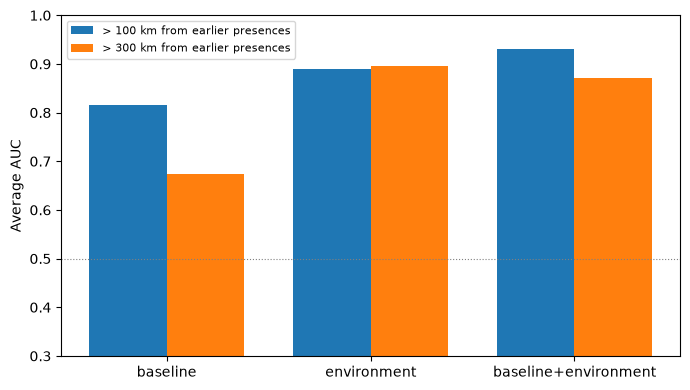


Saved: ..\data\processed\model_results_novel_v0.csv and ..\docs\figures\new_territory_test.png


In [25]:
# --- Cell 18: "new territory" test. Can the model find whales where nobody had seen one before? ---
# Run in the SAME session after Cells 14-17 (reuses table, ENV, COMBINED, make_model, auc, top_area_capture, TEST_YEARS, OUT_DIR, FIG_DIR).
# For each test year we only keep test points that are FAR from every presence recorded in earlier years
# (any month). That removes the "go where whales were seen before" shortcut: the seasonal baseline has no memory there.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

THRESHOLDS_KM = [100, 300]

def min_dist_km(lat, lon, plat, plon, chunk=500):
    """Distance (km, equirectangular approximation) from each point to the nearest past presence."""
    out = np.empty(len(lat))
    for a in range(0, len(lat), chunk):
        la, lo = lat[a:a + chunk, None], lon[a:a + chunk, None]
        dx = (lo - plon[None, :]) * 111.32 * np.cos(np.radians((la + plat[None, :]) / 2))
        dy = (la - plat[None, :]) * 110.57
        out[a:a + chunk] = np.sqrt(dx ** 2 + dy ** 2).min(axis=1)
    return out

rows = []
for year in TEST_YEARS:
    train = table[table["obs_year"] < year]
    past = train[train["presence"] == 1]
    test = table[table["obs_year"] == year].reset_index(drop=True)
    dist = min_dist_km(test["cell_center_lat"].values, test["cell_center_lon"].values,
                       past["cell_center_lat"].values, past["cell_center_lon"].values)
    scores = {"baseline": test["base_score"].values}
    for name, cols in [("environment", ENV), ("baseline+environment", COMBINED)]:
        scores[name] = make_model().fit(train[cols], train["presence"]).predict_proba(test[cols])[:, 1]
    for km in THRESHOLDS_KM:
        mask = dist > km
        y = test["presence"].values[mask]
        if y.sum() < 5 or (y == 0).sum() < 5:             # too few points for a meaningful AUC
            continue
        for name, s_all in scores.items():
            s = s_all[mask]
            _, capture = top_area_capture(s, y)
            rows.append({"test_year": year, "min_distance_km": km, "model": name, "AUC": round(auc(s, y), 3),
                         "presences_inside": round(capture, 3), "n_presence": int(y.sum()), "n_background": int((y == 0).sum())})
res4 = pd.DataFrame(rows)
if res4.empty:
    print("Not enough 'new territory' presences in the test years for any threshold. Nothing to report.")
else:
    print("=== New-territory test: test points farther than X km from every earlier presence ===")
    print("(For each X: AUC / share of presences in the top-10% area, averaged over the test years that had enough points)\n")
    print(res4.groupby(["min_distance_km", "model"])[["AUC", "presences_inside"]].mean().round(3).to_string())
    print("\nNumber of points per year (average):")
    print(res4.groupby("min_distance_km")[["n_presence", "n_background"]].mean().round(0).to_string())
    print("\nYears that contributed:", sorted(res4["test_year"].unique()))
    print("\nAUC per year and threshold:")
    print(res4.pivot_table(index=["min_distance_km", "test_year"], columns="model", values="AUC").to_string())

    fig, ax = plt.subplots(figsize=(7, 4))
    order = ["baseline", "environment", "baseline+environment"]
    for k, km in enumerate(sorted(res4["min_distance_km"].unique())):
        v = res4[res4["min_distance_km"] == km].groupby("model")["AUC"].mean().reindex(order)
        ax.bar(np.arange(3) + (k - 0.5) * 0.38, v.values, 0.38, label=f"> {km} km from earlier presences")
    ax.set_xticks(range(3)); ax.set_xticklabels(order)
    ax.axhline(0.5, color="grey", lw=0.8, ls=":"); ax.set_ylim(0.3, 1.0); ax.set_ylabel("Average AUC")
    ax.legend(fontsize=8); fig.tight_layout()
    fig.savefig(FIG_DIR / "new_territory_test.png", dpi=200)
    plt.show()
    res4.to_csv(OUT_DIR / "model_results_novel_v0.csv", index=False)
    print("\nSaved:", OUT_DIR / "model_results_novel_v0.csv", "and", FIG_DIR / "new_territory_test.png")